# TP4 – Procesamiento de arreglos

# Grupo N° 4

| Integrante | Legajo |
|---|---|
| *Pedro Stefoni Rey Iraola* | *64903* |
| *Vito Pensa Piccolo* | *63426* |
| *Javier Baltasar Pérez Losada* | *64589* |

**Fecha de entrega:** 26/11/2026

## 0. Datos, modelo y convenciones

La grabación `mtms-arrC1A.wav` (*CMU Microphone Array Database*) tiene 15 canales, $f_s = 16$ kHz y dura 34 s. Con el origen en el micrófono 7, las posiciones son (en cm):

$$p_m \in \{-48,\,-32,\,-24,\,-16,\,-12,\,-8,\,-4,\;0,\;4,\;8,\;12,\;16,\;24,\;32,\;48\}$$

Usamos el modelo de señal de arreglos lineales de la teórica:

$$\mathbf{x}(n) = \sqrt{M}\,\mathbf{v}(\phi_s)\,s(n) + \mathbf{i}(n) + \mathbf{w}(n)$$

donde $\mathbf{v}(\phi)$ es el vector de respuesta del arreglo (de norma 1), $\mathbf{i}(n)$ la interferencia y $\mathbf{w}(n)$ el ruido. Tomamos $c = 343$ m/s (aire a unos 20 °C).

**Convención de signos.** Siguiendo el consejo de la consigna, demodulamos multiplicando por $e^{+j2\pi F_c n/f_s}$. Esto baja a banda base la réplica que estaba en $-F_c$, que es la conjugada de la que dan los canales I/Q de la teórica ($\cos$ y $-\sin$). Entonces el vector de respuesta también queda conjugado:

$$v_m(\phi) = \frac{1}{\sqrt{M}}\,e^{+j2\pi F_c \tau_m}, \qquad \tau_m = \frac{d_m \sin\phi}{c}$$

con $d_m$ medido desde el primer micrófono del sub-arreglo hacia el lado del micrófono 14. Así, $\phi>0$ es una fuente del lado del micrófono 0 y $\phi<0$ una del lado del 14. Además, para un ULA queda $v_m(u) = e^{+j2\pi um}/\sqrt M$, así que una FFT entre sensores (`np.fft.fft`) calcula directamente $\mathbf{c}_{mf}^H(u)\,\mathbf{x}(n)$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal
from scipy.io import wavfile
from scipy.optimize import least_squares
from scipy.signal.windows import chebwin
from IPython.display import Audio, display

plt.rcParams["figure.dpi"] = 90

# ------------------------------------------------------------
# Parámetros
# ------------------------------------------------------------
C_SON = 343.0          # Velocidad del sonido [m/s] (aire a ~20 °C)
FC = 2000.0            # Frecuencia portadora de la consigna [Hz]
LAMBDA = C_SON / FC    # Longitud de onda en FC [m]
REF = 7                # Micrófono de referencia (el central)

# Posiciones de los 15 micrófonos [m], con el origen en el micrófono 7
POS = np.array([-48, -32, -24, -16, -12, -8, -4, 0, 4, 8, 12, 16, 24, 32, 48]) / 100

# Sub-arreglos de la consigna (clave: espaciamiento d en cm)
SUB = {4:  [3, 4, 5, 6, 7, 8, 9, 10, 11],
       8:  [1, 2, 3, 5, 7, 9, 11, 12, 13],
       16: [0, 1, 3, 7, 11, 13, 14]}

for d, idx in SUB.items():                       # Chequeo de la geometría: los tres tienen que ser ULA
    assert np.allclose(np.diff(POS[idx]), d / 100)

# Zonas [s] marcadas a partir del espectrograma de 1.c, dejando ~0.1 s de margen en los bordes
FRASES = [(0.60, 2.70), (5.10, 8.50), (11.20, 12.10), (13.20, 14.60), (15.90, 17.40), (18.60, 19.80),
          (20.75, 22.00), (23.20, 25.50), (26.75, 27.80), (29.00, 30.90), (31.90, 33.50)]   # locutor + interferencia
PAUSAS = [(2.95, 3.55), (4.10, 4.90), (9.05, 9.45), (10.20, 11.00), (12.45, 13.00), (14.85, 15.60),
          (17.70, 18.35), (20.05, 20.50), (22.30, 22.95), (28.15, 28.70), (31.15, 31.65)]   # sólo interferencia + ruido

# ------------------------------------------------------------
# Carga
# ------------------------------------------------------------
fs, datos = wavfile.read("mtms-arrC1A.wav")      # muestras x canales, int16
x = np.swapaxes(datos / 32768, 0, 1)             # canales x muestras, en [-1, 1)
x = x - x.mean(axis=1, keepdims=True)            # Eliminamos la continua de cada canal
N_MIC, N = x.shape
print(f"{N_MIC} canales, {N} muestras, {N/fs:.1f} s, fs = {fs} Hz")
print(f"λ(2 kHz) = {100*LAMBDA:.2f} cm")

15 canales, 543489 muestras, 34.0 s, fs = 16000 Hz
λ(2 kHz) = 17.15 cm


In [2]:
def db(p):
    return 10 * np.log10(np.maximum(p, 1e-20))


def en_zonas(t, zonas, dur=0.0):
    """True para los instantes (o tramas de duración dur que empiezan en t) que caen enteros en alguna zona."""
    m = np.zeros(len(t), bool)
    for a, b in zonas:
        m |= (t >= a) & (t + dur <= b)
    return m


def demodular(x, B, fc=FC):
    """Demodulación en banda base, pasa-bajos de corte B/2 y muestreo crítico (~B muestras/s)."""
    n = np.arange(x.shape[1])
    z = x * np.exp(2j * np.pi * fc / fs * n)                    # signo que sugiere la consigna
    h = signal.firwin(int(4 * fs / B) | 1, B / 2, fs=fs)        # FIR de fase lineal (ventana Hamming), dura 4/B
    y = signal.oaconvolve(z, h[None, :], mode="same", axes=1)   # "same" compensa el retardo del FIR
    D = int(fs // B)                                            # factor de submuestreo
    return y[:, ::D], n[::D] / fs


def v_plana(phi, idx, f=FC):
    """v(φ) de onda plana para los micrófonos idx (una columna por ángulo, norma 1). Signo de la demodulación."""
    d = POS[idx] - POS[idx][0]
    tau = np.outer(d, np.sin(np.radians(np.atleast_1d(phi)))) / C_SON
    return np.exp(2j * np.pi * f * tau) / np.sqrt(len(idx))


def tau_esferica(r, phi, pos=POS):
    """Tiempo de propagación desde una fuente puntual en (r, φ) hasta cada micrófono."""
    xf, yf = -r * np.sin(np.radians(phi)), r * np.cos(np.radians(phi))   # φ > 0: del lado del micrófono 0
    return np.sqrt((pos - xf)**2 + yf**2) / C_SON


def v_esferica(r, phi, idx, f=FC):
    """Igual que v_plana, pero con frente de onda esférico."""
    tau = tau_esferica(r, phi, POS[idx])
    v = np.exp(2j * np.pi * f * (tau - tau[0]))
    return v / np.sqrt(len(idx))


def correlacion(Z):
    """Matriz de correlación de muestras. Z: sensores x muestras."""
    return Z @ Z.conj().T / Z.shape[1]


def respuesta_dirigida(R, V):
    """R(φs) = v^H(φs) R v(φs) para cada columna de V."""
    return np.real(np.sum(V.conj() * (R @ V), axis=0))


def ancho_3dB(phi, P, phi0, vecindad=10):
    """Ancho a -3 dB del lóbulo que tiene su máximo a menos de `vecindad` grados de phi0."""
    cerca = np.where(np.abs(phi - phi0) <= vecindad)[0]
    i = cerca[np.argmax(P[cerca])]
    lo, hi = i, i
    while lo > 0 and P[lo] > P[i] / 2:
        lo -= 1
    while hi < len(phi) - 1 and P[hi] > P[i] / 2:
        hi += 1
    return phi[i], phi[hi] - phi[lo]

## 1. Espectrograma de frecuencia espacial

### 1.a — Elección del sub-arreglo

En un ULA, $d$ es el intervalo de muestreo espacial y la frecuencia espacial normalizada es

$$u = \frac{d\,\sin\phi}{\lambda}$$

Para que no haya aliasing en $-90° \le \phi \le 90°$ se tiene que cumplir la condición de Nyquist espacial:

$$d \le \frac{\lambda}{2} \quad\Longleftrightarrow\quad F \le \frac{c}{2d}$$

La resolución, en cambio, mejora con la apertura $L$ (distancia entre el primer y el último elemento): $\Delta\phi_{3\,\text{dB}} \approx \lambda / L$, y fuera de $\phi = 0$ la apertura efectiva es $L\cos\phi$. En 2 kHz es $\lambda = 17{,}15$ cm y $\lambda/2 = 8{,}6$ cm:

In [3]:
filas = []
for d, idx in SUB.items():
    L_ap = np.ptp(POS[idx])                       # Distancia entre el primer y el último elemento
    filas.append({
        "d [cm]": d,
        "M": len(idx),
        "d/λ": d / 100 / LAMBDA,
        "F máx sin aliasing c/2d [Hz]": C_SON / (2 * d / 100),
        "Apertura L [cm]": 100 * L_ap,
        "Δφ ≈ λ/L en 0° [°]": np.degrees(LAMBDA / L_ap),
        "Δφ ≈ λ/(L cos 38°) [°]": np.degrees(LAMBDA / (L_ap * np.cos(np.radians(38)))),
    })
display(pd.DataFrame(filas).set_index("d [cm]").round(2))

,M,d/λ,F máx sin aliasing c/2d [Hz],Apertura L [cm],Δφ ≈ λ/L en 0° [°],Δφ ≈ λ/(L cos 38°) [°]
d [cm],,,,,,
4,9,0.23,4287.50,32.0,30.71,38.97
8,9,0.47,2143.75,64.0,15.35,19.48
16,7,0.93,1071.88,96.0,10.24,12.99


**Elegimos $d = 8$ cm**, que es casi el óptimo $d = \lambda/2$:

- Con 16 cm es $d = 0{,}93\,\lambda$ y no se cumple Nyquist: una fuente en $\phi$ aparece también en $\phi'$, con $\sin\phi' = \sin\phi \pm \lambda/d$.
- Con 4 cm tampoco hay aliasing, pero con la misma cantidad de micrófonos tiene la mitad de apertura que el de 8 cm, o sea la mitad de resolución. Como vimos en la teórica, con $d<\lambda/2$ no se gana información.

### 1.b — Ancho de banda $B$

El modelo de la sección 0 vale bajo la condición *narrowband*, que acota $B$ por arriba:

1. **Producto tiempo–ancho de banda.** La señal tarda como máximo $\tau_{\max} = L/c = 0{,}64/343 = 1{,}87$ ms en atravesar el arreglo. Pedir $B\,\tau_{\max} \ll 1$ equivale a $B \ll 536$ Hz.
2. **Nyquist espacial en toda la banda.** La frecuencia más alta es $F_c + B/2$:

$$F_c + \frac{B}{2} \le \frac{c}{2d} = 2144\ \text{Hz} \quad\Longrightarrow\quad B \le 287\ \text{Hz}$$

Y por abajo:

3. **Cantidad de muestras.** Con muestreo crítico hay $B$ muestras por segundo. En el punto 2 hay que estimar $\mathbf R_{i+n}$ (de $9\times 9$) en una zona sin voz, y las pausas más largas duran 0,8 s. Para perder menos de 3 dB de SINR hace falta $N \ge 2M = 18$ (Reed–Mallett–Brennan), o sea $B \ge 23$ Hz. Además, al bajar $B$ empeora la resolución temporal.

La teórica sugiere típicamente $B < 1\%$ de $F_c$ (20 Hz). El rango razonable va entonces de unas decenas a un par de cientos de Hz. **Adoptamos $B = 50$ Hz** ($B\,\tau_{\max} = 0{,}09$) y en 1.e lo justificamos con mediciones.

Para demodular usamos un FIR pasa-bajos de fase lineal (ventana Hamming, corte en $B/2$, duración $4/B = 80$ ms, con el retardo compensado) y submuestreamos a $B$ muestras por segundo.

### 1.c — Espectrograma de frecuencia espacial

En cada tramo de 100 ms (con 50 % de overlap) calculamos el periodograma espacial con una FFT entre los 9 sensores (zero-padding a 256 puntos) y lo promediamos en el tiempo:

$$\hat P(u, t) = \frac{1}{N_t}\sum_{n \in t} \left| \mathbf{c}_{mf}^H(u)\,\mathbf{x}(n)\right|^2, \qquad |u| \le \frac{d}{\lambda} = 0{,}47$$

El eje derecho muestra el ángulo de cono, $\phi = \arcsin(u\,\lambda/d)$. Las barras marcan las zonas que usamos en el resto del TP: **frases** (locutor + interferencia) y **pausas** (sólo interferencia + ruido). Las marcamos a partir de esta figura, dejando unos 0,1 s de margen en los bordes de cada frase, que es más que los ±40 ms que "desparrama" el filtro.

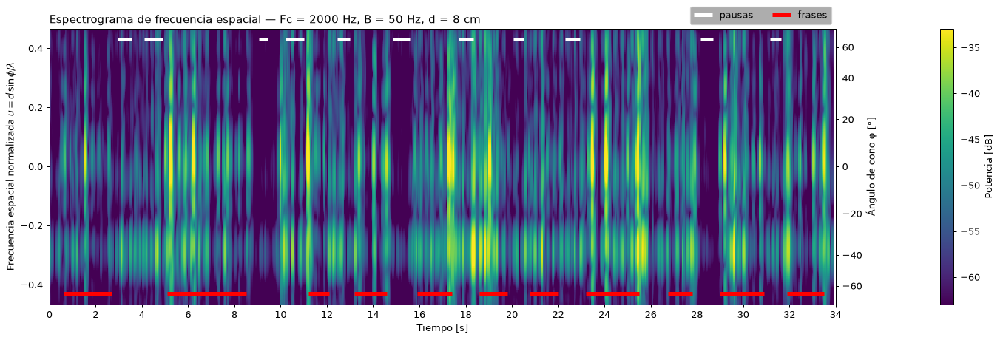

In [4]:
B = 50.0                                          # Ancho de banda elegido (ver 1.b y 1.e)
x8 = np.take(x, SUB[8], axis=0)                   # Sub-arreglo de 8 cm
y8, t8 = demodular(x8, B)


def espectrograma_espacial(y, t, T=0.1, nfft=256):
    """Periodograma espacial |c_mf^H(u) x(n)|², calculado con FFT entre sensores y promediado en tramos de T."""
    r = 1 / (t[1] - t[0])                         # muestras demoduladas por segundo
    L = max(int(round(T * r)), 1)
    salto = max(L // 2, 1)
    ini = np.arange(0, y.shape[1] - L + 1, salto)
    Y = np.fft.fftshift(np.fft.fft(y, n=nfft, axis=0), axes=0) / np.sqrt(len(y))
    P = np.stack([np.mean(np.abs(Y[:, i:i+L])**2, axis=1) for i in ini], axis=1)
    u = np.fft.fftshift(np.fft.fftfreq(nfft))     # frecuencia espacial normalizada
    return t[ini] + L / (2 * r), u, P


te, u, P = espectrograma_espacial(y8, t8)
u_max = 0.08 / LAMBDA                             # región visible: |u| ≤ d/λ


def u_a_phi(u):
    return np.degrees(np.arcsin(np.clip(u / u_max, -1, 1)))


def phi_a_u(phi):
    return u_max * np.sin(np.radians(phi))


fig, ax = plt.subplots(figsize=(15, 5), layout="constrained")
PdB = db(P)
vmax = np.percentile(PdB[np.abs(u) <= u_max], 99.5)
im = ax.pcolormesh(te, u, PdB, shading="auto", cmap="viridis", vmin=vmax - 30, vmax=vmax, rasterized=True)
for zonas, color, nombre, h in [(PAUSAS, "white", "pausas", 0.43), (FRASES, "red", "frases", -0.43)]:
    for k, (a, b) in enumerate(zonas):
        ax.plot([a, b], [h, h], color=color, lw=4, solid_capstyle="butt", label=nombre if k == 0 else None)
ax.set_ylim(-u_max, u_max)
ax.set_xticks(range(0, 35, 2))
ax.set_xlabel("Tiempo [s]")
ax.set_ylabel(r"Frecuencia espacial normalizada $u = d\,\sin\phi/\lambda$")
sec = ax.secondary_yaxis("right", functions=(u_a_phi, phi_a_u))
sec.set_yticks([-60, -40, -20, 0, 20, 40, 60])
sec.set_ylabel("Ángulo de cono φ [°]")
ax.set_title(f"Espectrograma de frecuencia espacial — Fc = {FC:.0f} Hz, B = {B:.0f} Hz, d = 8 cm", loc="left")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, facecolor="0.6")
fig.colorbar(im, ax=ax, label="Potencia [dB]", pad=0.08)
plt.show()

### 1.d — ¿Qué señales espaciales observamos?

En el espectrograma se ven dos líneas horizontales, es decir, dos fuentes con dirección fija:

- una en $u \approx 0$ ($\phi \approx 0°$), **intermitente**, con estructura de frases y pausas;
- otra en $u \approx -0{,}29$ ($\phi\approx -38°$), presente **durante todo el registro**, incluso en las pausas de la primera.

También hay lóbulos más débiles y rayas verticales que cubren todos los ángulos en los instantes más fuertes. Para separar fuentes reales de lóbulos laterales, promediamos la respuesta dirigida $R(\phi_s)=\mathbf c^H(\phi_s)\,\hat{\mathbf R}\,\mathbf c(\phi_s)$ en las frases y en las pausas, con y sin taper:

Frases | sin taper              | picos [°, dB rel. al máximo]: (-37.0, -2.4), (+2.0, 0.0), (+35.0, -8.9), (+60.0, -10.7)
Frases | taper Chebyshev -50 dB | picos [°, dB rel. al máximo]: (-38.5, -3.2), (+2.9, 0.0)
Pausas | sin taper              | picos [°, dB rel. al máximo]: (-38.0, 0.0), (-4.9, -6.8), (+65.0, -10.8)
Pausas | taper Chebyshev -50 dB | picos [°, dB rel. al máximo]: (-38.5, 0.0), (-1.2, -6.6)


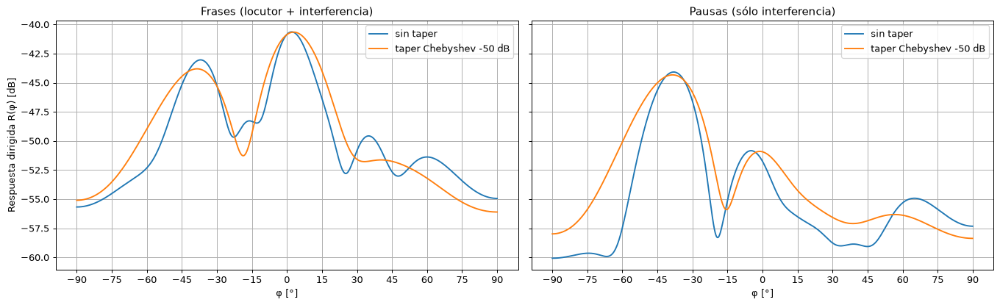


Lóbulo principal en frases: +2.0°   |   Lóbulo principal en pausas: -38.0°


In [5]:
PHI = np.arange(-90, 90.05, 0.1)                  # grilla de direcciones de observación

V8 = v_plana(PHI, SUB[8])
taper = chebwin(len(SUB[8]), 50)                  # Dolph-Chebyshev, lóbulos laterales a -50 dB
V8t = V8 * taper[:, None]
V8t /= np.linalg.norm(V8t, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True, layout="constrained")
for ax, zonas, nombre in zip(axes, (FRASES, PAUSAS), ("Frases (locutor + interferencia)", "Pausas (sólo interferencia)")):
    R = correlacion(y8[:, en_zonas(t8, zonas)])
    for V, etiqueta in [(V8, "sin taper"), (V8t, "taper Chebyshev -50 dB")]:
        Pz = respuesta_dirigida(R, V)
        ax.plot(PHI, db(Pz), label=etiqueta)
        picos, _ = signal.find_peaks(db(Pz), prominence=1)
        print(f"{nombre[:6]:6s} | {etiqueta:22s} | picos [°, dB rel. al máximo]: "
              + ", ".join(f"({PHI[i]:+.1f}, {db(Pz[i]/Pz.max()):.1f})" for i in picos))
    ax.set_title(nombre)
    ax.set_xlabel("φ [°]")
    ax.set_xticks(range(-90, 91, 15))
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("Respuesta dirigida R(φ) [dB]")
plt.show()

# Direcciones medidas en 2 kHz
R_fr = correlacion(y8[:, en_zonas(t8, FRASES)])
R_pa = correlacion(y8[:, en_zonas(t8, PAUSAS)])
PHI_LOC_2K = ancho_3dB(PHI, respuesta_dirigida(R_fr, V8), 0)[0]
PHI_RAD = ancho_3dB(PHI, respuesta_dirigida(R_pa, V8), -38)[0]
print(f"\nLóbulo principal en frases: {PHI_LOC_2K:+.1f}°   |   Lóbulo principal en pausas: {PHI_RAD:+.1f}°")

- **Lóbulos laterales.** Sin taper aparecen picos extra en +35° y +60° (frases) y en +65° (pausas), entre 9 y 11 dB por debajo del máximo. Con el taper Dolph-Chebyshev desaparecen, así que **no son fuentes**. El costo del taper es un lóbulo principal más ancho.
- **Energía cerca de 0° sin el locutor.** En las pausas, el pico que está entre −5° y −1° (a unos 7 dB de la radio) sobrevive al taper. Es energía que realmente llega desde ahí aunque el locutor esté callado. Puede ser un cooler, reflexiones o la cola de reverberación de la frase anterior; con este análisis no podemos separarlos.

**¿Quién es quién?** Apuntamos un delay-and-sum de banda ancha (15 micrófonos) a cada dirección y comparamos los espectros:

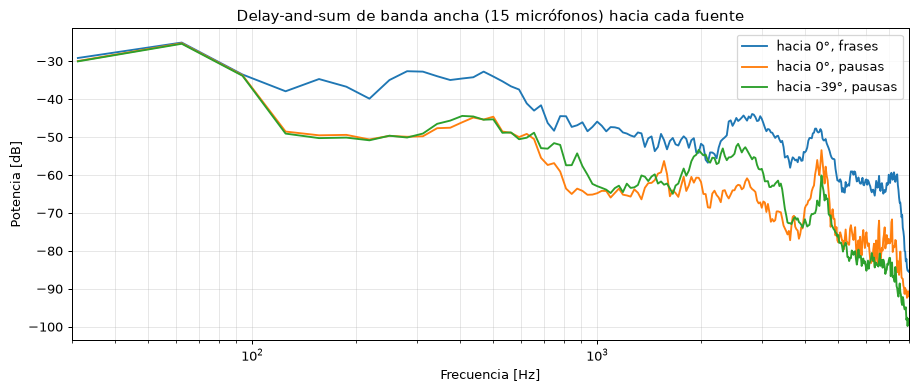

,20-100 Hz,100-1000 Hz,1000-3000 Hz,3000-5000 Hz,5000-8000 Hz
"hacia 0°, frases",-28.0,-36.9,-48.1,-51.0,-62.4
"hacia 0°, pausas",-28.3,-49.7,-63.1,-63.7,-77.9
"hacia -39°, pausas",-28.4,-49.1,-56.6,-65.9,-82.7


Delay-and-sum hacia 0° (primeros 17 s):


Delay-and-sum hacia -39° (primeros 17 s):


In [6]:
def das_banda_ancha(phi):
    """Delay-and-sum con los 15 micrófonos: retardos fraccionarios aplicados en frecuencia."""
    X = np.fft.rfft(x, axis=1)
    f = np.fft.rfftfreq(N, 1 / fs)
    tau = (POS - POS[REF]) * np.sin(np.radians(phi)) / C_SON
    return np.fft.irfft(np.mean(X * np.exp(2j * np.pi * f * tau[:, None]), axis=0), n=N)


das_0, das_rad = das_banda_ancha(0), das_banda_ancha(-39)


def espectro_en_zonas(s, zonas, L=512):
    f, t, S = signal.stft(s, fs, window="hamming", nperseg=L, noverlap=L // 2)
    return f, np.mean(np.abs(S[:, en_zonas(t, zonas)])**2, axis=1)


casos = [("hacia 0°, frases", das_0, FRASES), ("hacia 0°, pausas", das_0, PAUSAS),
         ("hacia -39°, pausas", das_rad, PAUSAS)]

plt.figure(figsize=(12, 4.5))
tabla = {}
for nombre, s, zonas in casos:
    f, Ps = espectro_en_zonas(s, zonas)
    plt.semilogx(f[1:], db(Ps[1:]), label=nombre)
    tabla[nombre] = {f"{lo}-{hi} Hz": db(np.mean(Ps[(f >= lo) & (f < hi)]))
                     for lo, hi in [(20, 100), (100, 1000), (1000, 3000), (3000, 5000), (5000, 8000)]}
plt.xlim(30, 8000)
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Potencia [dB]")
plt.title("Delay-and-sum de banda ancha (15 micrófonos) hacia cada fuente")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()
display(pd.DataFrame(tabla).T.round(1))

for nombre, s in [("Delay-and-sum hacia 0°", das_0), ("Delay-and-sum hacia -39°", das_rad)]:
    print(f"{nombre} (primeros 17 s):")
    display(Audio(s[:17 * fs], rate=fs))

- **0° es el locutor.** En las frases supera a las pausas por 12,8 dB entre 100 Hz y 1 kHz, y por 15,5 dB entre 5 y 8 kHz. Es una señal de banda ancha e intermitente, como una voz en vivo.
- **−39° es la radio AM.** Está todo el tiempo. Entre 1 y 3 kHz el haz hacia −39° recibe 6,5 dB más que el haz hacia 0°, pero arriba de 5 kHz casi no tiene señal (queda incluso 4,8 dB por debajo del otro haz). Es lo que se espera de una señal continua y de banda limitada.
- **Debajo de 100 Hz** los tres espectros coinciden (a menos de 0,5 dB). Es ruido de baja frecuencia (coolers, ventilación) que el arreglo no puede separar, porque $\lambda > 3{,}4$ m es mucho mayor que la apertura. Ahí no se distingue la voz.
- En las pausas también hay un pico angosto cerca de 4,4 kHz, más fuerte en el haz hacia 0°. No podemos atribuirlo a una fuente.

**¿Se cumple la hipótesis de campo lejano?** La distancia de Fraunhofer del sub-arreglo de 8 cm en 2 kHz es $2L^2/\lambda \approx 4{,}8$ m, y en una habitación es difícil que las fuentes estén tan lejos. Para comprobarlo, medimos el retardo de cada micrófono respecto del 7 con GCC-PHAT (300–5000 Hz) y ajustamos dos modelos:

$$\text{onda plana:}\;\; \tau_m = \frac{p_m\sin\phi}{c} + \tau_0 \qquad\qquad \text{onda esférica:}\;\; \tau_m = \frac{\lVert \mathbf{p}_m - \mathbf{r}_f \rVert}{c} + \tau_0$$

donde $\mathbf r_f$ es la posición de la fuente, a distancia $r$ y ángulo $\phi$.

Locutor (frases) | plana: φ =   +1.0°, error RMS =  99.9 µs  | esférica: r = 1.18 m, φ =   +0.6°, error RMS =   6.0 µs


Radio (pausas)   | plana: φ =  -39.3°, error RMS =  79.3 µs  | esférica: r = 1.23 m, φ =  -35.8°, error RMS =  48.3 µs


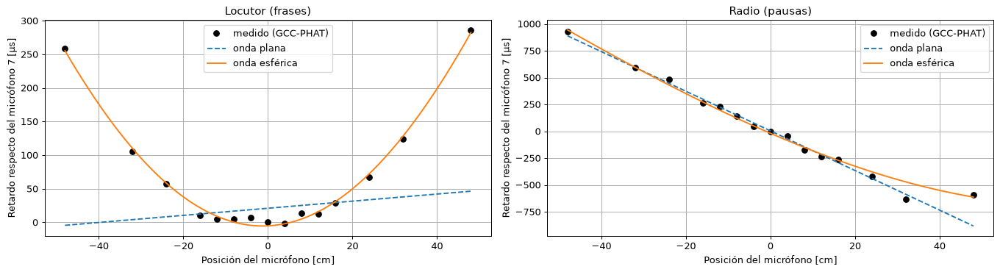


Desajuste de la onda plana frente a la esférica en 2000 Hz (locutor):
  sub-arreglo 8 cm : |v_plana^H v_esf|² = -1.48 dB, error de fase máximo = 95°
  15 micrófonos    : |v_plana^H v_esf|² = -4.17 dB, error de fase máximo = 171°


In [7]:
def retardos_gcc(zonas, fmin=300, fmax=5000):
    """Retardo de cada micrófono respecto del de referencia (GCC-PHAT, resolución de 0.02 muestras)."""
    f, t, S = signal.stft(x, fs, window="hamming", nperseg=1024, noverlap=512)
    m = en_zonas(t, zonas)
    G = np.mean(S[:, :, m] * S[REF][:, m].conj()[None], axis=2)   # espectro cruzado promedio
    G /= np.abs(G) + 1e-15                                        # PHAT: nos quedamos sólo con la fase
    b = (f >= fmin) & (f <= fmax)
    lags = np.arange(-60, 60.01, 0.02) / fs
    cc = np.real(G[:, b] @ np.exp(2j * np.pi * np.outer(f[b], lags)))
    return lags[np.argmax(cc, axis=1)]


def ajustar(tau, modelo, p0, limites=(-np.inf, np.inf)):
    residuo = lambda p: (modelo(p) - tau) * 1e6                   # en microsegundos
    sol = least_squares(residuo, p0, loss="soft_l1", f_scale=10, bounds=limites)
    return sol.x, np.sqrt(np.mean(residuo(sol.x)**2))


def modelo_plano(p):                              # p = (φ [rad], offset)
    return POS * np.sin(p[0]) / C_SON + p[1]


def modelo_esferico(p):                           # p = (r [m], φ [°], offset)
    return tau_esferica(p[0], p[1]) + p[2]


fig, axes = plt.subplots(1, 2, figsize=(15, 4), layout="constrained")
ajustes = {}
pp = np.linspace(POS[0], POS[-1], 200)
for ax, (nombre, zonas, phi0) in zip(axes, [("Locutor (frases)", FRASES, 0), ("Radio (pausas)", PAUSAS, -39)]):
    tau = retardos_gcc(zonas)
    p_pl, rms_pl = ajustar(tau, modelo_plano, [np.radians(phi0), 0])
    p_es, rms_es = ajustar(tau, modelo_esferico, [1.5, phi0, 0], ([0.2, -89, -1], [50, 89, 1]))
    ajustes[nombre.split()[0]] = {"phi_plana": np.degrees(p_pl[0]), "r": p_es[0], "phi_esf": p_es[1]}
    print(f"{nombre:17s}| plana: φ = {np.degrees(p_pl[0]):+6.1f}°, error RMS = {rms_pl:5.1f} µs"
          f"  | esférica: r = {p_es[0]:.2f} m, φ = {p_es[1]:+6.1f}°, error RMS = {rms_es:5.1f} µs")
    ax.plot(100 * POS, 1e6 * tau, "ko", label="medido (GCC-PHAT)")
    ax.plot(100 * pp, 1e6 * (pp * np.sin(p_pl[0]) / C_SON + p_pl[1]), "--", label="onda plana")
    ax.plot(100 * pp, 1e6 * (tau_esferica(p_es[0], p_es[1], pp) + p_es[2]), label="onda esférica")
    ax.set_title(nombre)
    ax.set_xlabel("Posición del micrófono [cm]")
    ax.set_ylabel("Retardo respecto del micrófono 7 [µs]")
    ax.grid(True)
    ax.legend()
plt.show()

PHI_S = ajustes["Locutor"]["phi_plana"]           # Dirección del locutor (modelo de onda plana)
R_LOC, PHI_LOC = ajustes["Locutor"]["r"], ajustes["Locutor"]["phi_esf"]

print(f"\nDesajuste de la onda plana frente a la esférica en {FC:.0f} Hz (locutor):")
for nombre, idx in [("sub-arreglo 8 cm", SUB[8]), ("15 micrófonos", list(range(15)))]:
    vp, ve = v_plana(PHI_S, idx)[:, 0], v_esferica(R_LOC, PHI_LOC, idx)
    fase = np.angle(ve * vp.conj() * np.exp(-1j * np.angle((ve * vp.conj())[idx.index(REF)])))
    print(f"  {nombre:17s}: |v_plana^H v_esf|² = {db(np.abs(np.vdot(vp, ve))**2):.2f} dB, "
          f"error de fase máximo = {np.degrees(np.abs(fase).max()):.0f}°")

**El locutor está en campo cercano.** Sus retardos forman claramente una parábola. La onda plana deja un error RMS de 99,9 µs y la esférica lo baja a **6,0 µs** (unas 17 veces menos), con la fuente a $r\approx 1{,}18$ m y $\phi \approx 0{,}6°$. En 2 kHz, usar la onda plana con el sub-arreglo de 8 cm implica hasta 95° de error de fase en los micrófonos de las puntas, y una pérdida $\lvert\mathbf v_{pl}^H \mathbf v_{esf}\rvert^2 = -1{,}5$ dB hacia el locutor ($-4{,}2$ dB con los 15 micrófonos).

Para la radio ningún modelo ajusta tan bien (79 µs el plano y 48 µs el esférico), así que no sacamos conclusiones sobre su distancia. Su dirección según la onda plana es $-39{,}3°$.

**Resumen de las señales observadas**

| Señal | Dirección | Cómo la reconocemos |
|---|---|---|
| Locutor | ≈ +1°, en campo cercano (≈ 1,2 m) | intermitente, banda ancha |
| Radio AM | ≈ −38° / −39° | continua, casi sin contenido sobre 5 kHz |
| Energía sin voz cerca de 0° | ≈ −5° a −1° | aparece en las pausas y sobrevive al taper |
| Ruido de baja frecuencia | sin dirección distinguible | igual en todos los haces debajo de 100 Hz |
| Coolers y reverberación | difusa | no les podemos asignar un pico propio; ver autovalores en 2.c |
| Picos en +35°, +60° y +65° | **no son fuentes** | lóbulos laterales: desaparecen con taper |

### 1.e — Verificación de las decisiones

**Sub-arreglo.** La teoría permite predecir dónde va a aparecer el aliasing con 16 cm. Para la radio:

$$\sin\phi' = \sin(-38°) + \frac{\lambda}{d} = -0{,}616 + 1{,}072 = 0{,}456 \quad\Longrightarrow\quad \phi' \approx +27°$$

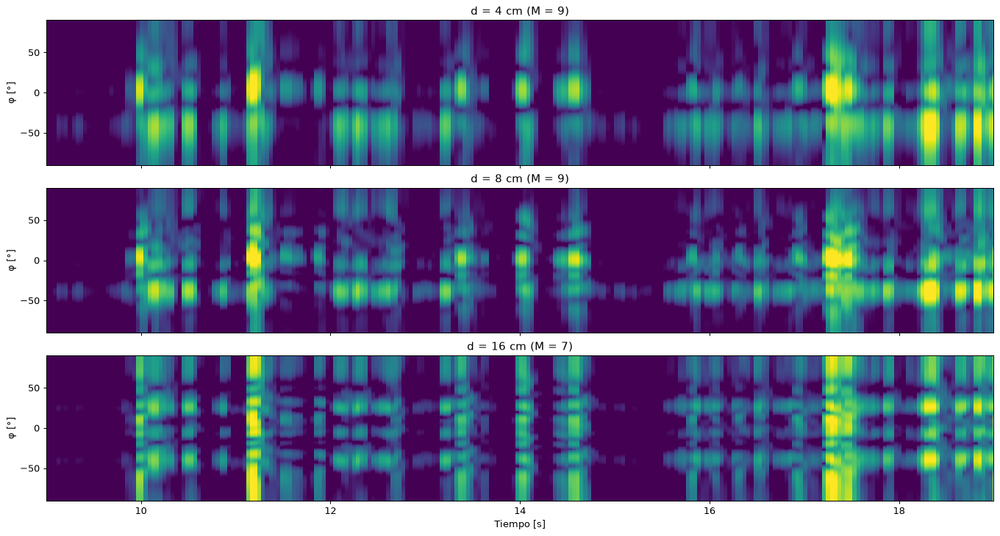

,pico radio [°],ancho radio medido [°],pico locutor [°],ancho locutor medido [°]
d [cm],,,,
4,-41.0,33.0,3.7,24.5
8,-38.0,18.6,2.0,16.1
16,-39.5,16.0,10.0,25.7


Réplica por aliasing predicha para la radio (-38.0°) con d = 16 cm: +27.1°
Pico medido: +25.8°, -0.0 dB respecto del máximo del espectro


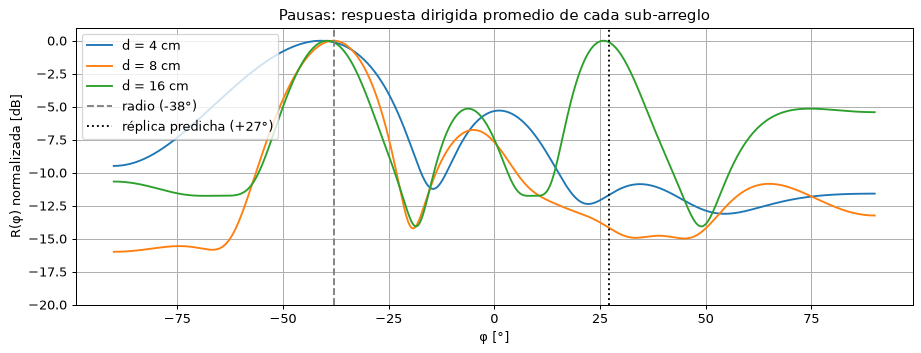

In [8]:
PHI_G = np.arange(-90, 90.5, 0.5)
fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True, layout="constrained")
curvas = {}
filas = []
for ax, (d, idx) in zip(axes, SUB.items()):
    yd, td = demodular(np.take(x, idx, axis=0), B)
    Yb = v_plana(PHI_G, idx).conj().T @ yd                    # direcciones x muestras
    L = int(round(0.1 / (td[1] - td[0])))
    ini = np.arange(0, yd.shape[1] - L + 1, L // 2)
    Pd = np.stack([np.mean(np.abs(Yb[:, i:i+L])**2, axis=1) for i in ini], axis=1)
    vmax = np.percentile(db(Pd), 99.5)
    ax.pcolormesh(td[ini] + 0.05, PHI_G, db(Pd), shading="auto", vmin=vmax - 25, vmax=vmax, rasterized=True)
    ax.set_xlim(9, 19)
    ax.set_ylabel("φ [°]")
    ax.set_title(f"d = {d} cm (M = {len(idx)})")

    V = v_plana(PHI, idx)
    P_pa = respuesta_dirigida(correlacion(yd[:, en_zonas(td, PAUSAS)]), V)
    P_fr = respuesta_dirigida(correlacion(yd[:, en_zonas(td, FRASES)]), V)
    curvas[d] = P_pa
    pr, wr = ancho_3dB(PHI, P_pa, -38)
    pl, wl = ancho_3dB(PHI, P_fr, 0)
    filas.append({"d [cm]": d, "pico radio [°]": pr, "ancho radio medido [°]": wr,
                  "pico locutor [°]": pl, "ancho locutor medido [°]": wl})
axes[-1].set_xlabel("Tiempo [s]")
plt.show()
display(pd.DataFrame(filas).set_index("d [cm]").round(1))

# Predicción de aliasing del sub-arreglo de 16 cm: sin φ' = sin φ ± λ/d
s_alias = np.sin(np.radians(PHI_RAD)) + LAMBDA / 0.16
PHI_ALIAS = np.degrees(np.arcsin(s_alias))
print(f"Réplica por aliasing predicha para la radio ({PHI_RAD:+.1f}°) con d = 16 cm: {PHI_ALIAS:+.1f}°")
phi_med = ancho_3dB(PHI, curvas[16], PHI_ALIAS)[0]
print(f"Pico medido: {phi_med:+.1f}°, {db(curvas[16][np.argmin(np.abs(PHI - phi_med))] / curvas[16].max()):.1f} dB "
      "respecto del máximo del espectro")

plt.figure(figsize=(12, 4))
for d, P_pa in curvas.items():
    plt.plot(PHI, db(P_pa / P_pa.max()), label=f"d = {d} cm")
plt.axvline(PHI_RAD, color="gray", ls="--", label=f"radio ({PHI_RAD:+.0f}°)")
plt.axvline(PHI_ALIAS, color="k", ls=":", label=f"réplica predicha ({PHI_ALIAS:+.0f}°)")
plt.ylim(-20, 1)
plt.xlabel("φ [°]")
plt.ylabel("R(φ) normalizada [dB]")
plt.title("Pausas: respuesta dirigida promedio de cada sub-arreglo")
plt.grid(True)
plt.legend()
plt.show()

- **16 cm:** en las pausas aparece una segunda "fuente" en +25,8°, **con la misma potencia que la radio**, a 1,3° de lo predicho. La línea fantasma se ve durante todo el registro y además arruina la estimación del locutor: su pico se corre a +10° y mide 25,7° de ancho. Queda descartado.
- **8 cm contra 4 cm:** ninguno tiene aliasing, pero el de 8 cm resuelve mejor. La radio mide 18,6° de ancho contra 33,0°, y el locutor 16,1° contra 24,5°. Son valores del orden de la predicción $\lambda/(L\cos\phi)$ (19,5° y 39,0° para la radio; 15,4° y 30,7° para el locutor), aunque la mejora medida (1,8 y 1,5 veces) no llega al factor 2 teórico.

Se confirma que **el de 8 cm es el óptimo** para $F_c = 2$ kHz.

**Ancho de banda.** Lo de 1.b son cotas. Para elegir dentro del rango necesitamos una métrica que mida lo que nos interesa: cuánto se puede separar la voz de la interferencia. Usamos el beamformer SMI del punto 2 (apuntado al locutor) y estimamos la SINR a su salida. Como no tenemos la voz limpia, suponemos que la interferencia es estacionaria e incorrelacionada con la voz. Entonces $P_Y = P_S + P_N$ y

$$\boxed{\widehat{\text{SINR}} = \frac{P_Y}{P_N} - 1}$$

donde $P_Y$ es la potencia de salida en las frases y $P_N$ en las pausas. **Cada pausa se evalúa con pesos entrenados en las otras** (validación cruzada), para no medir sobre los mismos datos con los que diseñamos el filtro. Como la potencia de la voz y de la radio dentro de la banda cambia con $B$, comparamos la **mejora** respecto de un solo micrófono. También medimos cuánta voz se pierde, $(P_Y-P_N)_{\text{SMI}} \,/\, (P_Y-P_N)_{\text{mic}}$, usando para el micrófono solo $\mathbf c = \sqrt M\,\mathbf e_7$, que tiene la misma ganancia (unitaria en módulo).

In [9]:
def smi(R, v):
    """Beamformer MVDR: c = R⁻¹v / (v^H R⁻¹ v)."""
    w = np.linalg.solve(R, v)
    return w / np.vdot(v, w)


def evaluar(y, t, pesos):
    """
    pesos(Z) devuelve c a partir de las muestras de entrenamiento Z (sensores x muestras).
    P_N: potencia de salida en las pausas. Cada pausa se evalúa con un c entrenado en las OTRAS pausas.
    P_Y: potencia de salida en las frases, con c entrenado en todas las pausas.
    """
    suma, n = 0.0, 0
    for k in range(len(PAUSAS)):
        c = pesos(y[:, en_zonas(t, PAUSAS[:k] + PAUSAS[k+1:])])
        s = c.conj() @ y[:, en_zonas(t, [PAUSAS[k]])]
        suma += np.sum(np.abs(s)**2)
        n += len(s)
    c = pesos(y[:, en_zonas(t, PAUSAS)])
    PY = np.mean(np.abs(c.conj() @ y[:, en_zonas(t, FRASES)])**2)
    return suma / n, PY


def sinr_dB(PN, PY):
    return db(PY / PN - 1)


def mic_solo(idx):
    """Un único micrófono (el 7) escrito como beamformer con la misma ganancia unitaria: c = √M e_7."""
    c = np.zeros(len(idx), complex)
    c[idx.index(REF)] = np.sqrt(len(idx))
    return c

,filtro 4/B [ms],TBWP = B·τmax,N en pausas,SINR 1 mic [dB],SINR SMI [dB],mejora SMI [dB],interf. SMI/MF [dB],voz SMI/1 mic [dB]
B [Hz],,,,,,,,
10,400.00,0.02,72,5.86,15.83,9.96,-10.06,-7.26
20,200.00,0.04,145,5.66,20.15,14.50,-10.26,-4.20
30,133.33,0.06,201,4.89,21.41,16.52,-8.98,-2.52
50,80.00,0.09,340,3.17,19.55,16.38,-8.18,-1.74
100,40.00,0.19,681,0.85,17.12,16.27,-6.60,-1.26
200,20.00,0.37,1351,-0.03,15.19,15.22,-5.31,-1.15
280,14.29,0.52,1881,0.79,14.92,14.13,-4.68,-1.50
500,8.00,0.93,3361,1.77,14.20,12.43,-3.36,-1.58
1000,4.00,1.87,6711,4.44,13.55,9.11,-1.60,-2.45


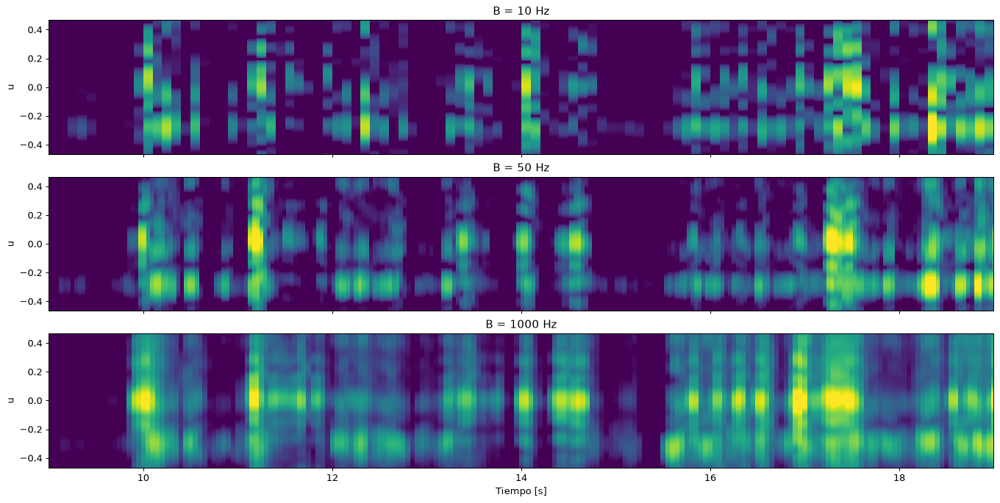

In [10]:
filas = []
v_s = v_plana(PHI_S, SUB[8])[:, 0]
tau_max = np.ptp(POS[SUB[8]]) / C_SON
c_mic = mic_solo(SUB[8])
for Bk in [10, 20, 30, 50, 100, 200, 280, 500, 1000]:
    yk, tk = demodular(x8, Bk)
    PN_m, PY_m = evaluar(yk, tk, lambda Z: c_mic)
    PN_f, PY_f = evaluar(yk, tk, lambda Z: v_s)
    PN_s, PY_s = evaluar(yk, tk, lambda Z: smi(correlacion(Z), v_s))
    filas.append({
        "B [Hz]": Bk,
        "filtro 4/B [ms]": 4000 / Bk,
        "TBWP = B·τmax": Bk * tau_max,
        "N en pausas": int(en_zonas(tk, PAUSAS).sum()),
        "SINR 1 mic [dB]": sinr_dB(PN_m, PY_m),
        "SINR SMI [dB]": sinr_dB(PN_s, PY_s),
        "mejora SMI [dB]": sinr_dB(PN_s, PY_s) - sinr_dB(PN_m, PY_m),
        "interf. SMI/MF [dB]": db(PN_s / PN_f),
        "voz SMI/1 mic [dB]": db((PY_s - PN_s) / (PY_m - PN_m)),
    })
tabla_B = pd.DataFrame(filas).set_index("B [Hz]")
display(tabla_B.round(2))

fig, axes = plt.subplots(3, 1, figsize=(15, 7.5), sharex=True, layout="constrained")
for ax, Bk in zip(axes, [10, 50, 1000]):
    yk, tk = demodular(x8, Bk)
    tt, uu, Pk = espectrograma_espacial(yk, tk)
    vmax = np.percentile(db(Pk[np.abs(uu) <= u_max]), 99.5)
    ax.pcolormesh(tt, uu, db(Pk), shading="auto", vmin=vmax - 25, vmax=vmax, rasterized=True)
    ax.set_ylim(-u_max, u_max)
    ax.set_xlim(9, 19)
    ax.set_ylabel("u")
    ax.set_title(f"B = {Bk} Hz")
axes[-1].set_xlabel("Tiempo [s]")
plt.show()

- **La mejora tiene un máximo ancho entre 30 y 100 Hz** (16,5, 16,4 y 16,3 dB con 30, 50 y 100 Hz).
- **Con $B$ grande** la mejora cae (15,2 dB con 200 Hz y 9,1 dB con 1 kHz) y el SMI saca cada vez menos radio que el filtro ajustado (8,2 dB menos con 50 Hz, pero sólo 1,6 dB menos con 1 kHz). En el espectrograma de 1 kHz las fuentes se ven más difusas. La caída empieza bastante antes de lo que sugiere $B\,\tau_{\max}$: con 200 Hz ($B\,\tau_{\max} = 0{,}37$) ya perdemos supresión. Nuestra interpretación es que en una sala reverberante no importa sólo el tiempo de tránsito por el arreglo, sino también el retardo de las reflexiones, que es mucho mayor. En una banda angosta, el camino directo y las reflexiones se suman como una única firma espacial; en una banda ancha, esa suma cambia con la frecuencia.
- **Con $B$ muy chico** la radio se suprime todavía más, pero **se empieza a cancelar la voz** ($-4{,}2$ dB con 20 Hz y $-7{,}3$ dB con 10 Hz). Lo atribuimos a la duración del filtro: con 10 Hz dura 0,4 s, tanto como la pausa más corta, así que mete voz en las muestras de "pausa" y el SMI aprende a cancelarla (en 2.d se ve lo que pasa cuando entra voz en $\hat{\mathbf R}$). En el punto 3, donde cada trama de entrenamiento queda entera dentro de una pausa, angostar más la banda sí sigue ayudando.

**$B = 50$ Hz** está en el máximo (a 0,14 dB del mejor valor), pierde sólo 1,7 dB de voz, da 5 muestras por tramo de 100 ms y deja 340 muestras de interferencia en las pausas.

## 2. Beamformer óptimo SMI

La señal deseada es la voz del locutor; la radio, los coolers y la reverberación son interferencia. Maximizando la SINR e imponiendo ganancia unitaria en la dirección de observación (MVDR), el beamformer óptimo es

$$\boxed{\mathbf{c}_o = \frac{\mathbf{R}_{i+n}^{-1}\,\mathbf{v}(\phi_s)}{\mathbf{v}^H(\phi_s)\,\mathbf{R}_{i+n}^{-1}\,\mathbf{v}(\phi_s)}}$$

Como no conocemos $\mathbf R_{i+n}$, el método SMI la reemplaza por la matriz de correlación de muestras, tomadas de una zona **sin la señal deseada**:

$$\hat{\mathbf R}_{i+n} = \frac1N \sum_{n=0}^{N-1} \mathbf x_{i+n}(n)\,\mathbf x_{i+n}^H(n)$$

Usamos el sub-arreglo de 8 cm, $B = 50$ Hz y $\phi_s = +1{,}0°$ (dirección del locutor según el ajuste de onda plana de 1.d).

### 2.a — Elección de la zona

Las dos pausas más largas duran 0,8 s (4,1–4,9 s y 10,2–11,0 s). Elegimos **4,1–4,9 s** porque, de las dos, es la que tiene menos energía relativa en la dirección del locutor (columna $R(\phi_s)/R(\phi_{radio})$). El criterio usa sólo la propia zona: no elegimos mirando el resultado.

Para ver cuánto depende el resultado de la zona, también entrenamos con cada pausa por separado y medimos la interferencia en las **demás**. La última columna es la pérdida de SINR que se espera por usar pocas muestras (Reed–Mallett–Brennan, para muestras gaussianas e independientes):

$$\mathbb E\{\rho\} = \frac{N+2-M}{N+1}$$

In [11]:
M8 = len(SUB[8])
phi_idx = lambda p: v_plana(p, SUB[8])[:, 0]
filas = []
c_todas = smi(R_pa, v_s)
for k, z in enumerate(PAUSAS):
    Z = y8[:, en_zonas(t8, [z])]
    R = correlacion(Z)
    c = smi(R, v_s)
    resto = y8[:, en_zonas(t8, PAUSAS[:k] + PAUSAS[k+1:])]      # pausas que no se usaron para entrenar
    fr = y8[:, en_zonas(t8, FRASES)]
    PN, PY = np.mean(np.abs(c.conj() @ resto)**2), np.mean(np.abs(c.conj() @ fr)**2)
    n = Z.shape[1]
    filas.append({
        "zona [s]": f"{z[0]:.2f}–{z[1]:.2f}",
        "N": n,
        "R(φs)/R(φradio) [dB]": db(respuesta_dirigida(R, np.c_[v_s, phi_idx(PHI_RAD)])).dot([1, -1]),
        "interf. SMI/MF [dB]": db(PN / np.mean(np.abs(v_s.conj() @ resto)**2)),
        "SINR [dB]": sinr_dB(PN, PY),
        "pérdida RMB esperada [dB]": db((n + 2 - M8) / (n + 1)),
    })
PN, PY = evaluar(y8, t8, lambda Z: smi(correlacion(Z), v_s))
PN_f, _ = evaluar(y8, t8, lambda Z: v_s)
n = int(en_zonas(t8, PAUSAS).sum())
filas.append({"zona [s]": "todas (val. cruzada)", "N": n, "R(φs)/R(φradio) [dB]": db(
    respuesta_dirigida(R_pa, np.c_[v_s, phi_idx(PHI_RAD)])).dot([1, -1]), "interf. SMI/MF [dB]": db(PN / PN_f),
    "SINR [dB]": sinr_dB(PN, PY), "pérdida RMB esperada [dB]": db((n + 2 - M8) / (n + 1))})
display(pd.DataFrame(filas).set_index("zona [s]").round(2))

,N,R(φs)/R(φradio) [dB],interf. SMI/MF [dB],SINR [dB],pérdida RMB esperada [dB]
zona [s],,,,,
2.95–3.55,30,-8.02,-6.07,18.05,-1.30
4.10–4.90,41,-8.96,-6.45,19.98,-0.92
9.05–9.45,20,-8.25,-3.20,14.95,-2.08
10.20–11.00,41,-8.18,-6.27,18.95,-0.92
12.45–13.00,28,-7.14,-6.66,18.99,-1.40
14.85–15.60,38,-8.18,-7.12,17.15,-1.00
17.70–18.35,33,-8.03,-6.13,19.03,-1.17
20.05–20.50,23,-8.34,-5.17,13.88,-1.76
22.30–22.95,33,-7.93,-5.26,17.13,-1.17


- La zona elegida da $N = 41 \approx 4{,}5\,M$ y una SINR de 20,0 dB.
- Entre zonas hay mucha dispersión, de 13,9 a 20,0 dB. Las cuatro peores tienen $N \le 28$.
- Con todas las pausas (validación cruzada), el SMI saca 8,2 dB más de interferencia que el filtro ajustado; con una sola zona, entre 3,2 y 7,1 dB. O sea que una zona suelta pierde entre 1,1 y 5,0 dB de supresión, bastante más que lo que predice RMB (0,9 a 2,1 dB). **No coincide**, y creemos que es porque la fórmula supone interferencia estacionaria, mientras que la radio cambia de contenido de una pausa a otra.
- En SINR, la zona elegida empata con todas las pausas (20,0 contra 19,6 dB): suprime menos, pero también atenúa menos la voz. Esa diferencia es chica frente a la dispersión entre zonas, así que no podemos decir que una sea mejor.

### 2.b — Patrón beam $\;|C(\phi)|^2 = |\mathbf c^H\,\mathbf v(\phi)|^2$

filtro espacialmente ajustado (MF)  | |C(φradio)|² =  -18.3 dB | mínimos en -69°, -44°, -27°, -13°, +15°, +30°, +47°, +76° | máximo: -0.0 dB en +1°
SMI, zona 4.1–4.9 s                 | |C(φradio)|² =   -5.0 dB | mínimos en -46°, -28°, -7°, +33° | máximo: +1.1 dB en -17°
SMI, todas las pausas               | |C(φradio)|² =   -8.6 dB | mínimos en -42°, -25°, -7°, +12°, +39°, +58° | máximo: +0.2 dB en +2°


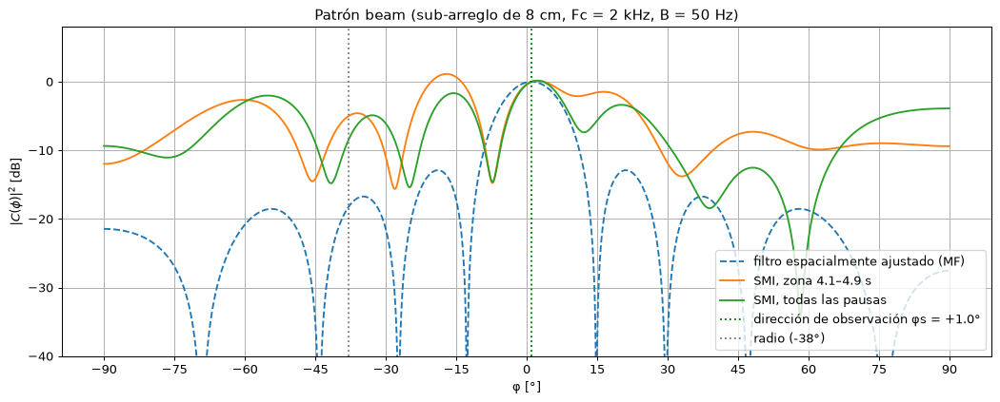

In [12]:
ZONA = (4.10, 4.90)                               # zona única elegida
c_zona = smi(correlacion(y8[:, en_zonas(t8, [ZONA])]), v_s)

patrones = [("filtro espacialmente ajustado (MF)", v_s, "--"),
            (f"SMI, zona {ZONA[0]:.1f}–{ZONA[1]:.1f} s", c_zona, "-"),
            ("SMI, todas las pausas", c_todas, "-")]

plt.figure(figsize=(14, 5))
for nombre, c, ls in patrones:
    C = db(np.abs(c.conj() @ V8)**2)              # patrón beam |C(φ)|² = |c^H v(φ)|²
    plt.plot(PHI, C, ls, label=nombre)
    ceros, _ = signal.find_peaks(-C, prominence=3)
    print(f"{nombre:36s}| |C(φradio)|² = {db(np.abs(np.vdot(c, phi_idx(PHI_RAD)))**2):6.1f} dB | mínimos en "
          + ", ".join(f"{PHI[i]:+.0f}°" for i in ceros) + f" | máximo: {C.max():+.1f} dB en {PHI[np.argmax(C)]:+.0f}°")
plt.axvline(PHI_S, color="green", ls=":", label=f"dirección de observación φs = {PHI_S:+.1f}°")
plt.axvline(PHI_RAD, color="gray", ls=":", label=f"radio ({PHI_RAD:+.0f}°)")
plt.ylim(-40, 8)
plt.xticks(range(-90, 91, 15))
plt.xlabel("φ [°]")
plt.ylabel(r"$|C(\phi)|^2$ [dB]")
plt.title("Patrón beam (sub-arreglo de 8 cm, Fc = 2 kHz, B = 50 Hz)")
plt.grid(True)
plt.legend(loc="lower right")
plt.show()

- Los tres valen 0 dB en $\phi_s$, por la restricción de ganancia unitaria.
- El **filtro espacialmente ajustado** es el patrón clásico de un ULA de 9 elementos: primer lóbulo lateral cerca de $-13$ dB y ceros equiespaciados en $u$.
- El **SMI** rompe esa regularidad. En los dos casos pone un mínimo en $-7°$, al lado del lóbulo principal, cerca de donde en 1.d vimos energía aun sin el locutor.
- **Los lóbulos laterales del SMI son altos:** con una sola zona llegan a $+1{,}1$ dB en $-17°$, o sea más ganancia que en la dirección de observación. No es un error: el SMI no minimiza la ganancia en todas las direcciones, sino la potencia de la interferencia **que midió**, y alrededor de $-17°$ en las pausas casi no hay energía (ver 1.d). El precio es que una fuente nueva en esa dirección entraría amplificada.
- Lo más llamativo es que **no hay un cero profundo en la dirección de la radio**. En $-38°$ el SMI tiene $-5{,}0$ dB (una zona) y $-8{,}6$ dB (todas las pausas), ¡más ganancia que el filtro ajustado ($-18{,}3$ dB)! Sin embargo, deja pasar mucha menos radio.

### 2.c — La firma espacial de la interferencia

El patrón beam se calcula con ondas planas $\mathbf v(\phi)$, pero la radio no llega como una onda plana. Su firma *medida* es el autovector principal $\mathbf u_1$ de $\hat{\mathbf R}_{i+n}$:

In [13]:
lam, U = np.linalg.eigh(R_pa)                     # autovalores de R_i+n (orden creciente)
u1 = U[:, -1]                                     # autovector principal: la "firma" medida de la interferencia
print("Autovalores de R_i+n [dB rel. al mayor]:", np.round(db(lam[::-1] / lam[-1]), 1))
print(f"λ1 / traza = {lam[-1]/lam.sum():.2f}")
V_busq = v_plana(PHI, SUB[8])
parecido = np.abs(V_busq.conj().T @ u1)**2
print(f"Mejor onda plana para u1: φ = {PHI[np.argmax(parecido)]:+.1f}°, |v^H u1|² = {parecido.max():.2f}")
print()
for nombre, c, _ in patrones:
    print(f"{nombre:36s}| onda plana |c^H v(φradio)|² = {db(np.abs(np.vdot(c, phi_idx(PHI_RAD)))**2):6.1f} dB"
          f"   | firma medida |c^H u1|² = {db(np.abs(np.vdot(c, u1))**2):6.1f} dB")

Autovalores de R_i+n [dB rel. al mayor]: [  0.   -7.7 -13.8 -16.3 -17.9 -19.8 -20.5 -24.4 -25.8]
λ1 / traza = 0.78


Mejor onda plana para u1: φ = -38.0°, |v^H u1|² = 0.80

filtro espacialmente ajustado (MF)  | onda plana |c^H v(φradio)|² =  -18.3 dB   | firma medida |c^H u1|² =  -14.1 dB
SMI, zona 4.1–4.9 s                 | onda plana |c^H v(φradio)|² =   -5.0 dB   | firma medida |c^H u1|² =  -24.5 dB
SMI, todas las pausas               | onda plana |c^H v(φradio)|² =   -8.6 dB   | firma medida |c^H u1|² =  -50.6 dB


- $\lambda_1$ concentra el 78 % de la potencia de la interferencia. El resto se reparte entre los otros 8 autovalores: es la parte difusa (reverberación, coolers, ruido).
- La onda plana que más se parece a $\mathbf u_1$ es justamente la de $-38°$, pero el parecido es de sólo $|\mathbf v^H\mathbf u_1|^2 = 0{,}80$.
- Sobre esa firma real, el filtro ajustado deja pasar $-14{,}1$ dB y el SMI de una zona $-24{,}5$ dB. Con todas las pausas el cero es de **$-50{,}6$ dB**.

O sea que **el SMI sí anula a la radio, pero en su firma real** (con las reflexiones incluidas) y no en la onda plana. Por eso el patrón beam solo no alcanza para juzgar un beamformer adaptativo en una sala reverberante. Ojo: el $-50{,}6$ dB se mide con los mismos datos del entrenamiento, así que es optimista. En datos no usados, la interferencia total baja 8,2 dB respecto del filtro ajustado.

### 2.d — Comparación cuantitativa

Sumamos algunas variantes: filtro ajustado y SMI con el vector de dirección esférico de 1.d, SMI con taper ($\mathbf v \to \mathbf t \circ \mathbf v$, Dolph-Chebyshev de $-50$ dB, renormalizado) y, como contraejemplo, un beamformer cuya $\hat{\mathbf R}$ se estima con **todo** el audio, o sea con la voz adentro. $G_{bf} = M\,|\mathbf c^H\mathbf v(\phi_s)|^2 / |\mathbf c|^2$ es la ganancia de beamforming de la teórica (frente a ruido blanco).

In [14]:
v_e = v_esferica(R_LOC, PHI_LOC, SUB[8])
v_st = v_s * taper
v_st = v_st / np.linalg.norm(v_st)
R_total = correlacion(y8)                         # incluye las frases: NO es R_i+n

metodos = [
    ("1 micrófono",                 lambda Z: c_mic, v_s),
    ("MF onda plana",               lambda Z: v_s, v_s),
    ("MF onda esférica",            lambda Z: v_e, v_e),
    ("SMI, una zona",               lambda Z: c_zona, v_s),
    ("SMI, todas las pausas",       lambda Z: smi(correlacion(Z), v_s), v_s),
    ("SMI + taper Cheb. -50 dB",    lambda Z: smi(correlacion(Z), v_st), v_st),
    ("SMI esférico",                lambda Z: smi(correlacion(Z), v_e), v_e),
    ("con voz en R (todo el audio)", lambda Z: smi(R_total, v_s), v_s),
]
PN_ref, PY_ref = evaluar(y8, t8, lambda Z: c_mic)
filas = []
for nombre, pesos, v_obs in metodos:
    PN, PY = evaluar(y8, t8, pesos)
    if nombre == "SMI, una zona":                 # la evaluamos sólo en las pausas que no usa
        resto = y8[:, en_zonas(t8, [z for z in PAUSAS if z != ZONA])]
        PN = np.mean(np.abs(c_zona.conj() @ resto)**2)
    c = pesos(y8[:, en_zonas(t8, PAUSAS)])
    filas.append({
        "beamformer": nombre,
        "SINR [dB]": sinr_dB(PN, PY),
        "mejora vs 1 mic [dB]": sinr_dB(PN, PY) - sinr_dB(PN_ref, PY_ref),
        "voz vs 1 mic [dB]": db((PY - PN) / (PY_ref - PN_ref)),
        "G_bf (ruido blanco) [dB]": db(M8 * np.abs(np.vdot(c, v_obs))**2 / np.vdot(c, c).real),
        "|c^H u1|² [dB]": db(np.abs(np.vdot(c, u1))**2),
    })
display(pd.DataFrame(filas).set_index("beamformer").round(2))

,SINR [dB],mejora vs 1 mic [dB],voz vs 1 mic [dB],G_bf (ruido blanco) [dB],|c^H u1|² [dB]
beamformer,,,,,
1 micrófono,3.17,0.00,0.00,0.00,-0.59
MF onda plana,11.15,7.97,-1.96,9.54,-14.13
MF onda esférica,12.92,9.75,-0.99,9.54,-15.64
"SMI, una zona",19.98,16.81,0.43,4.36,-24.45
"SMI, todas las pausas",19.55,16.38,-1.74,5.36,-50.56
SMI + taper Cheb. -50 dB,18.48,15.31,-0.23,4.32,-43.12
SMI esférico,20.08,16.91,-1.74,5.18,-53.30
con voz en R (todo el audio),2.20,-0.97,-12.96,0.63,-25.43


### Conclusiones del punto 2

- **Filtro espacialmente ajustado.** Mejora la SINR 8,0 dB. Su $G_{bf}$ es exactamente $10\log_{10}9 = 9{,}54$ dB, como predice la teórica, pero eso vale para ruido blanco, y acá la interferencia es direccional.
- **SMI.** Con una sola zona de 0,8 s mejora **16,8 dB** (SINR de 20,0 dB): casi 9 dB más que el filtro ajustado, con los mismos 9 micrófonos. A cambio, su $G_{bf}$ cae de 9,5 a 4,4 dB: "gasta" grados de libertad en cancelar la interferencia y queda más sensible al ruido incorrelacionado y a los errores.
- **Taper.** Acá no ayuda: con todas las pausas, la SINR baja 1,1 dB (18,5 contra 19,6 dB) y $G_{bf}$ cae a 4,3 dB. El taper sirve para protegerse de interferencias que $\hat{\mathbf R}$ no capturó, y acá la dominante está en todas las pausas.
- **Campo cercano.** En el filtro ajustado, la onda esférica gana 1,8 dB de SINR, cerca de los 1,5 dB que predice $\lvert\mathbf v_{pl}^H\mathbf v_{esf}\rvert^2$. En el SMI casi no cambia nada (20,1 contra 19,6 dB).
- **Entrenar con la voz adentro es desastroso:** la voz cae **13 dB** y la SINR (2,2 dB) queda **peor que con un solo micrófono** (3,2 dB). El vector de dirección nunca coincide exactamente con la voz real (reflexiones, campo cercano), y el MVDR trata lo que no coincide como interferencia y lo cancela. Por eso la teórica pide estimar $\hat{\mathbf R}_{i+n}$ sin la señal deseada.

Todo esto vale para una banda de 50 Hz alrededor de 2 kHz. Para recuperar la voz hay que hacerlo en toda la banda, que es el punto 3.

## 3. Beamforming por sub-bandas (opcional)

**Banco de filtros con la FFT.** Cortamos los 15 canales en tramas de largo $L$, con ventana de Hamming y 50 % de overlap, y a cada una le calculamos la FFT:

$$X_m(k, \ell) = \sum_{n=0}^{L-1} w(n)\,x_m(\ell H + n)\,e^{-j2\pi kn/L}, \qquad H = \frac{L}{2}$$

Cada bin $k$ es la señal demodulada desde $F_k = k f_s/L$, filtrada por la ventana y submuestreada cada $H$ muestras: lo mismo que en el punto 1, pero para $L/2+1$ portadoras a la vez. El ancho de banda equivalente de ruido de la ventana de Hamming es de aproximadamente $1{,}36\,f_s/L$. En cada bin aplicamos un beamformer, $Y(k,\ell) = \mathbf c_k^H\,\mathbf X(k,\ell)$, y reconstruimos con IFFT y overlap-add, usando también una ventana de síntesis. Verificamos que, si el beamformer deja pasar un solo micrófono, la salida es exactamente ese micrófono.

**Signo.** `rfft` usa $e^{-j}$, que es la convención de la teórica, así que acá el vector de dirección **no** va conjugado.

In [15]:
def stft(sen, L):
    """STFT con ventana de Hamming y 50 % de overlap. Devuelve (canales x tramas x bins) y el inicio de cada trama."""
    H = L // 2
    w = signal.get_window("hamming", L)           # periódica: w(n) + w(n + L/2) = 1.08
    sp = np.pad(sen, ((0, 0), (L, L)))
    K = 1 + (sp.shape[1] - L) // H
    ind = np.arange(L) + H * np.arange(K)[:, None]
    return np.fft.rfft(sp[:, ind] * w, axis=-1), (np.arange(K) * H - L) / fs


def istft(Y, L):
    """Overlap-add con ventana de síntesis (reconstrucción por mínimos cuadrados)."""
    H = L // 2
    w = signal.get_window("hamming", L)
    tramas = np.fft.irfft(Y, n=L, axis=-1) * w
    y = np.zeros(H * (len(Y) - 1) + L)
    norma = np.zeros_like(y)
    for k, trama in enumerate(tramas):
        y[k*H:k*H+L] += trama
        norma[k*H:k*H+L] += w**2
    return (y / np.maximum(norma, 1e-12))[L:L+N]


# Chequeo: si el "beamformer" deja pasar sólo el micrófono 7, la salida tiene que ser x_7
S, _ = stft(x, 1024)
print(f"Error máximo de reconstrucción: {np.abs(istft(S[REF], 1024) - x[REF]).max():.1e}")


def corr_bins(S, tramas):
    """R(f) para cada bin: (bins x M x M)."""
    Z = S[:, tramas, :].transpose(2, 0, 1)
    return Z @ Z.conj().transpose(0, 2, 1) / Z.shape[2]


def cargar(R, gamma):
    """Carga diagonal proporcional a la potencia media de cada bin."""
    M = R.shape[1]
    pot = np.einsum("fmm->f", R).real / M
    return R + (gamma * pot + 1e-15)[:, None, None] * np.eye(M)


def mvdr_bins(R, a, gamma):
    """c(f) = R⁻¹a / (a^H R⁻¹ a), bin por bin."""
    w = np.linalg.solve(cargar(R, gamma), a[..., None])[..., 0]
    return w / np.sum(a.conj() * w, axis=1, keepdims=True)


def a_modelo(f, tau, ref):
    """Vector de dirección por bin, relativo al micrófono de referencia. rfft usa e^{-j}: no va conjugado."""
    return np.exp(-2j * np.pi * np.outer(f, tau - tau[ref]))


def estimar_rtf(Ry, Rn, ref):
    """RTF por blanqueo de covarianza: autovector principal de L⁻¹ R_y L⁻ᴴ, con R_i+n = L Lᴴ."""
    Lc = np.linalg.cholesky(cargar(Rn, 1e-6))
    Li = np.linalg.inv(Lc)
    _, Q = np.linalg.eigh(Li @ Ry @ Li.conj().transpose(0, 2, 1))
    h = (Lc @ Q[:, :, -1:])[..., 0]
    return h / h[:, ref:ref+1]

Error máximo de reconstrucción: 4.4e-16


**Beamformer por bin.** Usamos MVDR-SMI. $\hat{\mathbf R}_k$ se estima sólo con tramas que caen enteras dentro de las pausas, y le sumamos una carga diagonal:

$$\mathbf c_k = \frac{(\hat{\mathbf R}_k + \delta_k\mathbf I)^{-1}\,\mathbf a_k}{\mathbf a_k^H\,(\hat{\mathbf R}_k + \delta_k\mathbf I)^{-1}\,\mathbf a_k}, \qquad \delta_k = \gamma\,\frac{\operatorname{tr}\hat{\mathbf R}_k}{M}$$

La carga equivale a agregar ruido blanco ficticio: limita $|\mathbf c_k|^2$ y hace al MVDR más robusto (con $\gamma\to\infty$ se vuelve el filtro ajustado). Además, normalizamos $\mathbf a_k$ para que valga **1 en el micrófono 7**. Así, $\mathbf c_k^H\mathbf a_k = 1$ significa "la voz sale como llega al micrófono 7", y las salidas se pueden comparar directamente con ese micrófono. Probamos tres $\mathbf a_k$:

1. **Onda plana** hacia $\phi_s$.
2. **Onda esférica** desde la posición $(r, \phi)$ ajustada en 1.d.
3. **RTF** (función de transferencia relativa) estimada de los datos. Los modelos geométricos ignoran las reflexiones, que en 2.c vimos que importan, así que estimamos directamente cómo llega la voz a cada micrófono. En las frases es $\mathbf R_y = \sigma_s^2\,\mathbf h\,\mathbf h^H + \mathbf R_{i+n}$. Factorizando $\mathbf R_{i+n} = \mathbf L\mathbf L^H$ (Cholesky, como en la teórica) y blanqueando queda

$$\mathbf L^{-1}\,\mathbf R_y\,\mathbf L^{-H} = \sigma_s^2\,\tilde{\mathbf h}\,\tilde{\mathbf h}^H + \mathbf I, \qquad \tilde{\mathbf h} = \mathbf L^{-1}\mathbf h$$

Entonces $\tilde{\mathbf h}$ es proporcional al autovector principal $\mathbf q_{\max}$ de la matriz blanqueada, y

$$\boxed{\mathbf h \propto \mathbf L\,\mathbf q_{\max}, \qquad \mathbf a_k = \frac{\mathbf h}{h_7}}$$

Las frases sólo se usan para estimar $\mathbf a_k$. $\hat{\mathbf R}_k$ sigue saliendo **sólo de las pausas**, así que no volvemos a tener el problema de cancelación de 2.d.

**Evaluación.** Usamos la misma $\widehat{\text{SINR}}$ de antes, medida entre 100 y 7500 Hz sobre la señal ya reconstruida, para comparar todos los $L$ sobre los mismos tramos de tiempo. Dejamos afuera lo que está por debajo de 100 Hz porque ahí no se distingue la voz (1.d). Las pausas se evalúan con validación cruzada, y la RTF se estima con la mitad de las frases y se evalúa en la otra mitad.

In [16]:
SOS_VOZ = signal.butter(8, [100, 7500], "bandpass", fs=fs, output="sos")


def filtrar(s, banda=None):
    sos = SOS_VOZ if banda is None else signal.butter(8, banda, "bandpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, s)


def mascara_t(zonas):
    return en_zonas(np.arange(N) / fs, zonas)


def evaluar_stft(L, direccion, gamma=0.01, adaptativo=True, idx=range(15), bandas=(None,)):
    """
    Misma métrica que en el punto 2, pero medida sobre la señal temporal reconstruida (mismos tramos para todo L).
    direccion: "plana", "esferica" o "rtf". La RTF se estima con la mitad de las frases y se evalúa en la otra.
    """
    idx = list(idx)
    ref = idx.index(REF)
    S, t0 = stft(x[idx], L)
    f = np.fft.rfftfreq(L, 1 / fs)
    dur = L / fs
    tramas = lambda zonas: en_zonas(t0, zonas, dur)          # sólo tramas enteramente dentro de las zonas
    en_pausas = tramas(PAUSAS)

    def salida(c):
        return istft(np.einsum("fm,mkf->kf", c.conj(), S), L)

    if direccion == "rtf":
        particiones = [(FRASES[::2], FRASES[1::2]), (FRASES[1::2], FRASES[::2])]
    else:
        particiones = [(None, FRASES)]

    acum = np.zeros((len(bandas), 4))                        # suma P_N, n_N, suma P_Y, n_Y
    for frases_est, frases_eval in particiones:
        if direccion == "rtf":
            a = estimar_rtf(corr_bins(S, tramas(frases_est)), corr_bins(S, en_pausas), ref)
        elif direccion == "plana":
            a = a_modelo(f, POS[idx] * np.sin(np.radians(PHI_S)) / C_SON, ref)
        else:
            a = a_modelo(f, tau_esferica(R_LOC, PHI_LOC, POS[idx]), ref)

        def pesos(m):
            if not adaptativo:                               # filtro ajustado, con la misma restricción c^H a = 1
                return a / np.sum(np.abs(a)**2, axis=1, keepdims=True)
            return mvdr_bins(corr_bins(S, m), a, gamma)

        for k in range(len(PAUSAS)):                         # validación cruzada sobre las pausas
            y = salida(pesos(en_pausas & ~tramas([PAUSAS[k]])))
            sel = mascara_t([PAUSAS[k]])
            for i, banda in enumerate(bandas):
                acum[i, :2] += np.sum(filtrar(y, banda)[sel]**2), sel.sum()
        y = salida(pesos(en_pausas))
        sel = mascara_t(frases_eval)
        for i, banda in enumerate(bandas):
            acum[i, 2:] += np.sum(filtrar(y, banda)[sel]**2), sel.sum()

    res = []
    for i, banda in enumerate(bandas):
        PN, PY = acum[i, 0] / acum[i, 1], acum[i, 2] / acum[i, 3]
        r = filtrar(x[REF], banda)
        PN_m, PY_m = np.mean(r[mascara_t(PAUSAS)]**2), np.mean(r[mascara_t(FRASES)]**2)
        res.append({"SINR [dB]": sinr_dB(PN, PY), "mejora [dB]": sinr_dB(PN, PY) - sinr_dB(PN_m, PY_m),
                    "interf. vs mic 7 [dB]": db(PN / PN_m), "voz vs mic 7 [dB]": db((PY - PN) / (PY_m - PN_m)),
                    "SINR mic 7 [dB]": sinr_dB(PN_m, PY_m), "tramas de entrenamiento": int(en_pausas.sum())})
    return res

### 3.a — Elección de $L$

El punto 1 sugiere $B$ entre 30 y 100 Hz. Con $1{,}36\,f_s/L$, eso da $L = 256$ o $512$ (85 y 43 Hz). Además, para estimar matrices de $15\times15$ queremos al menos $2M = 30$ tramas.

In [17]:
LS = [256, 512, 1024, 2048, 4096]
filas = []
for L in LS:
    fila = {"L": L, "dur. [ms]": 1000 * L / fs, "ENBW ≈ 1.36 fs/L [Hz]": 1.36 * fs / L}
    for direc in ["plana", "esferica", "rtf"]:
        r = evaluar_stft(L, direc, gamma=0.01)[0]
        fila[f"SINR {direc} [dB]"] = r["SINR [dB]"]
    fila["tramas entren."] = r["tramas de entrenamiento"]
    filas.append(fila)
print(f"SINR de un solo micrófono (mic 7): {r['SINR mic 7 [dB]']:.2f} dB")
display(pd.DataFrame(filas).set_index("L").round(2))

SINR de un solo micrófono (mic 7): 9.81 dB


,dur. [ms],ENBW ≈ 1.36 fs/L [Hz],SINR plana [dB],SINR esferica [dB],SINR rtf [dB],tramas entren.
L,,,,,,
256,16.0,85.00,12.57,13.51,17.70,817
512,32.0,42.50,13.93,14.26,18.71,396
1024,64.0,21.25,15.12,14.92,19.61,187
2048,128.0,10.62,16.00,15.67,19.98,81
4096,256.0,5.31,15.81,15.58,19.96,29


**La predicción no se cumple:** con los tres vectores de dirección el máximo está en **$L = 2048$** (10,6 Hz), y con 4096 ya no mejora. Creemos que la diferencia viene de lo que penalizaba a un $B$ chico en el punto 1: allá el filtro de demodulación largo metía voz en las pausas, mientras que acá cada trama de entrenamiento está entera dentro de una pausa. Sin ese problema, angostar la banda sigue ayudando, porque cada bin queda mejor descripto por una única firma espacial (reflexiones incluidas), hasta que empiezan a faltar tramas.

Nos quedamos con **$L = 2048$**: empata con 4096 para la RTF (19,98 contra 19,96 dB) y tiene 81 tramas de entrenamiento, contra 29, que es menos que $2M$. Con la misma carga ($\gamma = 0{,}01$), en todos los $L$ la RTF le saca unos 4 dB al mejor modelo geométrico.

### 3.b — Carga diagonal

In [18]:
L_STFT = 2048
filas = []
for gamma in [0, 1e-3, 1e-2, 1e-1, 1]:
    fila = {"γ": gamma}
    for direc in ["plana", "esferica", "rtf"]:
        r = evaluar_stft(L_STFT, direc, gamma=gamma)[0]
        fila[f"SINR {direc} [dB]"] = r["SINR [dB]"]
        fila[f"voz {direc} [dB]"] = r["voz vs mic 7 [dB]"]
    filas.append(fila)
display(pd.DataFrame(filas).set_index("γ").round(2))

,SINR plana [dB],voz plana [dB],SINR esferica [dB],voz esferica [dB],SINR rtf [dB],voz rtf [dB]
γ,,,,,,
0.000,15.10,-9.44,15.17,-6.85,19.88,-0.93
0.001,15.27,-9.33,15.28,-6.75,19.94,-0.92
0.010,16.00,-8.61,15.67,-6.28,19.98,-0.87
0.100,17.05,-6.61,16.14,-5.10,19.37,-0.71
1.000,16.30,-4.43,15.88,-3.63,17.41,-0.53


Con los modelos geométricos la carga ayuda, y el mejor valor probado es $\gamma = 0{,}1$. En la onda plana, la SINR sube de 15,10 a 17,05 dB y la pérdida de voz baja de 9,4 a 6,6 dB, porque se limita cuánto puede "aprovechar" el MVDR el desajuste de $\mathbf a_k$ para cancelar la voz. Con la RTF, que casi no tiene desajuste, la carga prácticamente no cambia nada hasta $\gamma = 0{,}01$, y después empeora. Usamos $\gamma = 0{,}1$ para los modelos geométricos y $\gamma = 0{,}01$ para la RTF.

### 3.c — ¿La RTF apunta al locutor?

Como la RTF se estima de los datos, podría haber capturado la radio. Para chequearlo la comparamos con ondas planas $\mathbf v_k(\phi)$ de todas las direcciones, promediando entre 300 Hz y 4 kHz la cantidad $|\mathbf v_k^H(\phi)\,\mathbf a_k|^2 \,/\, (\lVert\mathbf v_k\rVert^2\,\lVert\mathbf a_k\rVert^2)$, que vale 1 si son proporcionales.

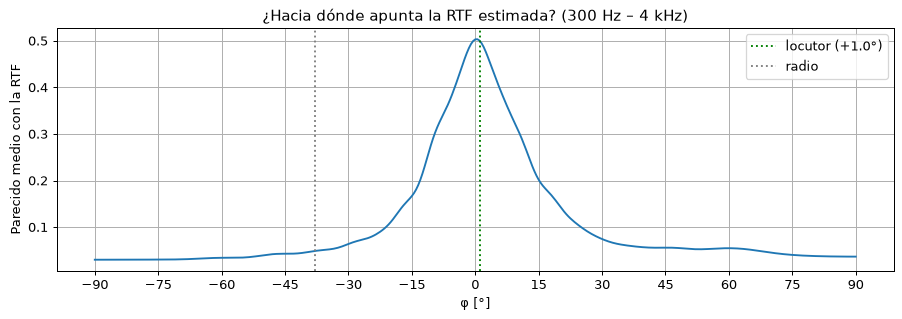

Máximo en φ = +0.5°, parecido = 0.50


In [19]:
S, t0 = stft(x, L_STFT)
f_bins = np.fft.rfftfreq(L_STFT, 1 / fs)
dur = L_STFT / fs
a_rtf = estimar_rtf(corr_bins(S, en_zonas(t0, FRASES, dur)), corr_bins(S, en_zonas(t0, PAUSAS, dur)), REF)

# ¿A qué dirección apunta la RTF estimada? Parecido con ondas planas, promediado entre 300 Hz y 4 kHz
b = (f_bins >= 300) & (f_bins <= 4000)
parecido = []
for p in PHI_G:
    a_p = a_modelo(f_bins[b], POS * np.sin(np.radians(p)) / C_SON, REF)
    cos2 = np.abs(np.sum(a_p.conj() * a_rtf[b], axis=1))**2 / (15 * np.sum(np.abs(a_rtf[b])**2, axis=1))
    parecido.append(cos2.mean())
parecido = np.array(parecido)
plt.figure(figsize=(12, 3.5))
plt.plot(PHI_G, parecido)
plt.axvline(PHI_S, color="green", ls=":", label=f"locutor ({PHI_S:+.1f}°)")
plt.axvline(PHI_RAD, color="gray", ls=":", label="radio")
plt.xticks(range(-90, 91, 15))
plt.xlabel("φ [°]")
plt.ylabel("Parecido medio con la RTF")
plt.title("¿Hacia dónde apunta la RTF estimada? (300 Hz – 4 kHz)")
plt.grid(True)
plt.legend()
plt.show()
print(f"Máximo en φ = {PHI_G[np.argmax(parecido)]:+.1f}°, parecido = {parecido.max():.2f}")

El máximo está en **+0,5°**, o sea en el locutor, y en la dirección de la radio no hay nada. Pero el parecido máximo es de sólo **0,50**: la mitad de la RTF no la explica ninguna onda plana. Ahí están la curvatura del frente de onda y las reflexiones que los modelos geométricos ignoran.

### 3.d — Comparación de beamformers

Con $L = 2048$ comparamos el filtro ajustado y el MVDR, cada uno con los tres vectores de dirección, y además el MVDR con RTF usando sólo el sub-arreglo de 8 cm. Para ver dónde actúa cada uno, repetimos las métricas por banda.

L = 2048, banda 100–7500 Hz. SINR del mic 7: 9.81 dB


,SINR [dB],mejora [dB],interf. vs mic 7 [dB],voz vs mic 7 [dB]
MF plana (delay-and-sum),12.95,3.14,-6.10,-2.97
MF esférica,13.38,3.57,-5.90,-2.34
MF con RTF,13.39,3.58,-3.90,-0.32
MVDR plana,17.05,7.24,-13.85,-6.61
MVDR esférica,16.14,6.34,-11.44,-5.10
MVDR RTF,19.98,10.18,-11.04,-0.87
"MVDR RTF, sólo 8 cm",19.41,9.60,-10.37,-0.76


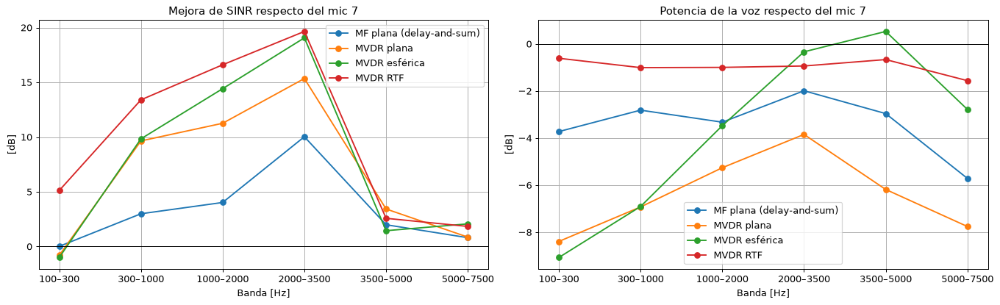

SINR del mic 7 por banda [dB]:    13.8    8.9    8.3    8.0    8.8   14.4
MF plana (delay-and-sum)  mejora:    0.0    3.0    4.0   10.0    2.0    0.8   | voz:   -3.7   -2.8   -3.3   -2.0   -3.0   -5.7
MVDR plana                mejora:   -0.8    9.6   11.3   15.3    3.4    0.9   | voz:   -8.4   -6.9   -5.3   -3.8   -6.2   -7.8
MVDR esférica             mejora:   -1.0    9.8   14.4   19.1    1.4    2.1   | voz:   -9.1   -6.9   -3.5   -0.3    0.5   -2.8
MVDR RTF                  mejora:    5.1   13.4   16.6   19.7    2.6    1.8   | voz:   -0.6   -1.0   -1.0   -0.9   -0.7   -1.6


In [20]:
BANDAS = [None, (100, 300), (300, 1000), (1000, 2000), (2000, 3500), (3500, 5000), (5000, 7500)]
CONFIGS = {
    "MF plana (delay-and-sum)": dict(direccion="plana", adaptativo=False),
    "MF esférica":              dict(direccion="esferica", adaptativo=False),
    "MF con RTF":               dict(direccion="rtf", adaptativo=False),
    "MVDR plana":               dict(direccion="plana", gamma=0.1),
    "MVDR esférica":            dict(direccion="esferica", gamma=0.1),
    "MVDR RTF":                 dict(direccion="rtf", gamma=0.01),
    "MVDR RTF, sólo 8 cm":      dict(direccion="rtf", gamma=0.01, idx=SUB[8]),
}
resultados = {n: evaluar_stft(L_STFT, bandas=BANDAS, **cfg) for n, cfg in CONFIGS.items()}

cols = ["SINR [dB]", "mejora [dB]", "interf. vs mic 7 [dB]", "voz vs mic 7 [dB]"]
print(f"L = {L_STFT}, banda 100–7500 Hz. SINR del mic 7: {resultados['MVDR RTF'][0]['SINR mic 7 [dB]']:.2f} dB")
display(pd.DataFrame({n: {c: r[0][c] for c in cols} for n, r in resultados.items()}).T.round(2))

etiquetas = [f"{lo}–{hi}" for lo, hi in BANDAS[1:]]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
for nombre in ["MF plana (delay-and-sum)", "MVDR plana", "MVDR esférica", "MVDR RTF"]:
    axes[0].plot(etiquetas, [r["mejora [dB]"] for r in resultados[nombre][1:]], "o-", label=nombre)
    axes[1].plot(etiquetas, [r["voz vs mic 7 [dB]"] for r in resultados[nombre][1:]], "o-", label=nombre)
for ax, titulo in zip(axes, ["Mejora de SINR respecto del mic 7", "Potencia de la voz respecto del mic 7"]):
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(titulo)
    ax.set_xlabel("Banda [Hz]")
    ax.set_ylabel("[dB]")
    ax.grid(True)
    ax.legend()
plt.show()
print("SINR del mic 7 por banda [dB]:  " + " ".join(f"{r['SINR mic 7 [dB]']:6.1f}" for r in resultados["MVDR RTF"][1:]))
for nombre in ["MF plana (delay-and-sum)", "MVDR plana", "MVDR esférica", "MVDR RTF"]:
    print(f"{nombre:25s} mejora: " + " ".join(f"{r['mejora [dB]']:6.1f}" for r in resultados[nombre][1:])
          + "   | voz: " + " ".join(f"{r['voz vs mic 7 [dB]']:6.1f}" for r in resultados[nombre][1:]))

- **El MVDR con RTF es claramente el mejor:** mejora **10,2 dB** la SINR y casi no toca la voz ($-0{,}9$ dB, y entre $-0{,}6$ y $-1{,}6$ dB en todas las bandas). El delay-and-sum mejora 3,1 dB.
- **El MVDR con modelos geométricos** saca mucha interferencia (hasta 13,9 dB), pero se lleva mucha voz ($-6{,}6$ dB con onda plana y $-5{,}1$ dB con esférica). Entre 1 y 3,5 kHz la esférica es claramente mejor que la plana (mejora de 14,4 y 19,1 dB contra 11,3 y 15,3 dB, perdiendo mucha menos voz). Sin embargo, en el total, que está pesado por potencia, la plana queda 0,9 dB arriba. No hay un ganador claro entre las dos.
- **A baja frecuencia los modelos geométricos fallan:** por debajo de 1 kHz pierden entre 7 y 9 dB de voz, y de 100 a 300 Hz quedan **peor que un solo micrófono** ($-0{,}8$ y $-1{,}0$ dB). Ahí $\lambda$ es mucho mayor que los espaciamientos, y un error chico en $\mathbf a_k$ alcanza para que el MVDR cancele la voz.
- **Usar los 15 micrófonos** suma 0,6 dB respecto de los 9 de 8 cm. Con este esquema no hace falta que el arreglo sea uniforme: $\mathbf a_k$ vale para cualquier geometría, y el MVDR decide en cada bin cómo usar cada micrófono.
- **Arriba de 3,5 kHz** ninguno de los cuatro métodos graficados mejora más de 3,4 dB. En 5–7,5 kHz el micrófono solo ya parte de una SINR más alta (14,4 dB contra unos 8 a 9 dB en las bandas del medio). En 3,5–5 kHz eso no pasa; creemos que influye que ahí la radio cae y que el pico de 4,4 kHz llega más por el lado de 0°, cerca de la voz. Además, por encima de 4,3 kHz ni siquiera el espaciamiento de 4 cm cumple Nyquist.

**Limitaciones de la métrica.** No tenemos la voz limpia. La $\widehat{\text{SINR}}$ cuenta como señal todo lo que aparece cuando habla el locutor, **incluida su reverberación**, que según la consigna es interferencia. Además, la columna "voz vs mic 7" favorece a la RTF por construcción, porque su objetivo es la voz tal como llega a ese micrófono, con sus reflexiones. Parte de lo que "pierden" los modelos geométricos puede ser desreverberación, y sin una referencia limpia no podemos separar cuánto. Lo que sí es claro es el caso de 100–300 Hz, donde quedan peor que el micrófono solo.

### 3.e — Resultado final

Para las figuras y los audios estimamos los pesos con todas las pausas (y la RTF con todas las frases). La celda también compara la reducción de interferencia en esas pausas con la de validación cruzada, para ver cuánto hay de sobreajuste.

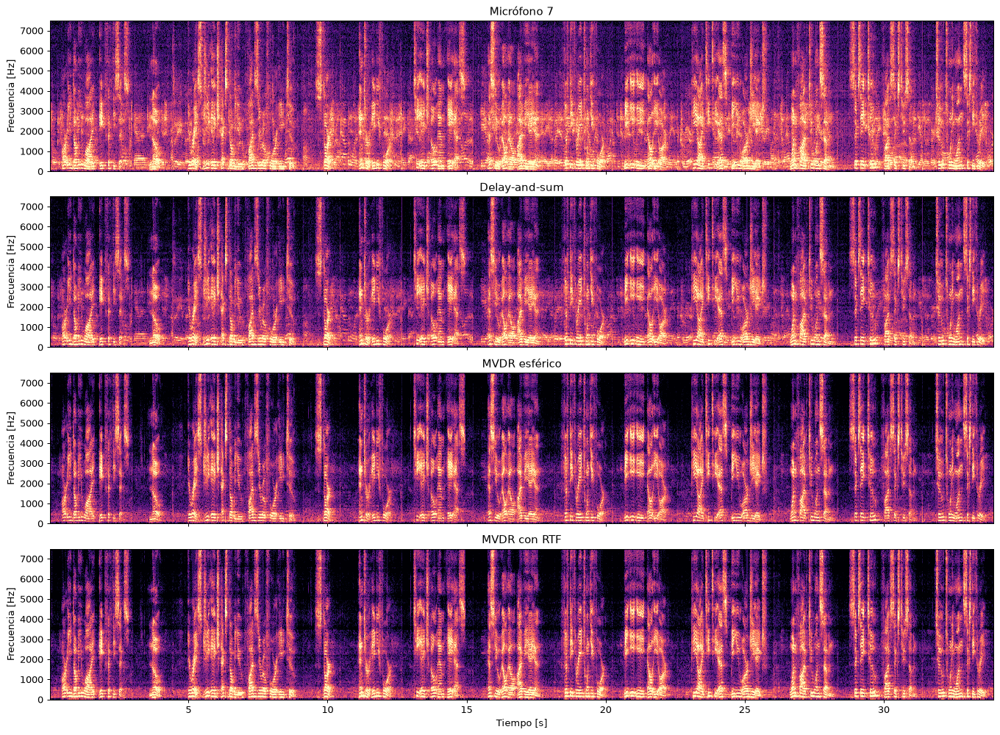

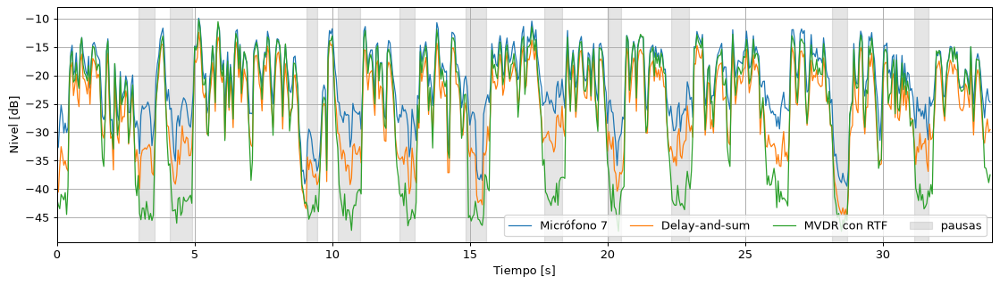

Delay-and-sum   interferencia vs mic 7:  en las pausas usadas para entrenar =   -6.1 dB   |   validación cruzada =   -6.1 dB
MVDR esférico   interferencia vs mic 7:  en las pausas usadas para entrenar =  -12.1 dB   |   validación cruzada =  -11.4 dB
MVDR con RTF    interferencia vs mic 7:  en las pausas usadas para entrenar =  -12.1 dB   |   validación cruzada =  -11.0 dB
Micrófono 7


Delay-and-sum


MVDR esférico


MVDR con RTF


In [21]:
# Salidas finales: R_i+n con todas las pausas (y RTF con todas las frases)
S, t0 = stft(x, L_STFT)
Rn_f = corr_bins(S, en_zonas(t0, PAUSAS, dur))
a_pl = a_modelo(f_bins, POS * np.sin(np.radians(PHI_S)) / C_SON, REF)
a_es = a_modelo(f_bins, tau_esferica(R_LOC, PHI_LOC), REF)

pesos_finales = {
    "delay_and_sum": a_pl / 15,
    "mvdr_esferico": mvdr_bins(Rn_f, a_es, 0.1),
    "mvdr_rtf":      mvdr_bins(Rn_f, a_rtf, 0.01),
}
salidas = {"mic7": filtrar(x[REF])}
for nombre, c in pesos_finales.items():
    salidas[nombre] = filtrar(istft(np.einsum("fm,mkf->kf", c.conj(), S), L_STFT))

titulos = {"mic7": "Micrófono 7", "delay_and_sum": "Delay-and-sum",
           "mvdr_esferico": "MVDR esférico", "mvdr_rtf": "MVDR con RTF"}

fig, axes = plt.subplots(4, 1, figsize=(15, 11), sharex=True, sharey=True, layout="constrained")
for ax, (nombre, s) in zip(axes, salidas.items()):
    f, t, Sx = signal.spectrogram(s, fs, window="hamming", nperseg=512, noverlap=384)
    ax.pcolormesh(t, f, db(Sx), shading="auto", cmap="magma", vmin=-105, vmax=-45, rasterized=True)
    ax.set_title(titulos[nombre])
    ax.set_ylabel("Frecuencia [Hz]")
    ax.set_ylim(0, 7500)
axes[-1].set_xlabel("Tiempo [s]")
plt.show()

# Nivel en el tiempo (RMS cada 50 ms): se ve cuánto baja el fondo en las pausas
plt.figure(figsize=(15, 3.8))
paso = int(0.05 * fs)
for nombre in ["mic7", "delay_and_sum", "mvdr_rtf"]:
    s = salidas[nombre]
    nivel = [db(np.mean(s[i:i+paso]**2)) for i in range(0, N - paso, paso)]
    plt.plot(np.arange(len(nivel)) * paso / fs, nivel, label=titulos[nombre], lw=1)
for k, (a, b_) in enumerate(PAUSAS):
    plt.axvspan(a, b_, color="gray", alpha=0.2, label="pausas" if k == 0 else None)
plt.xlim(0, N / fs)
plt.xlabel("Tiempo [s]")
plt.ylabel("Nivel [dB]")
plt.grid(True)
plt.legend(ncol=4)
plt.show()

# Estos pesos se entrenaron con TODAS las pausas: comparamos con la validación cruzada
en_p = mascara_t(PAUSAS)
pot_ref = np.mean(salidas["mic7"][en_p]**2)
for nombre, config in [("delay_and_sum", "MF plana (delay-and-sum)"), ("mvdr_esferico", "MVDR esférica"),
                       ("mvdr_rtf", "MVDR RTF")]:
    print(f"{titulos[nombre]:15s} interferencia vs mic 7:  en las pausas usadas para entrenar = "
          f"{db(np.mean(salidas[nombre][en_p]**2) / pot_ref):6.1f} dB   |   validación cruzada = "
          f"{resultados[config][0]['interf. vs mic 7 [dB]']:6.1f} dB")

# Audios (guardamos también los .wav en ./audio)
Path("audio").mkdir(exist_ok=True)
for nombre, s in salidas.items():
    wavfile.write(f"audio/{nombre}.wav", fs, np.int16(0.9 * 32767 * s / np.max(np.abs(s))))
    print(titulos[nombre])
    display(Audio(s, rate=fs))

### Conclusiones del punto 3

- **Poco sobreajuste.** Con el MVDR-RTF, la interferencia baja 12,1 dB en las pausas usadas para entrenar y 11,0 dB en validación cruzada. El segundo número es el que vale para un tramo nuevo.
- En el nivel en el tiempo se ve el efecto: en las pausas el fondo del MVDR-RTF queda muy por debajo del micrófono 7 y también del delay-and-sum, mientras que en las frases los picos de la voz se mantienen cerca del original.
- **Lo decisivo es el vector de dirección.** El mismo MVDR, entrenado con las mismas muestras, pasa de mejorar 6–7 dB con modelos geométricos a 10,2 dB con la RTF, y la pérdida de voz baja de 5–7 dB a menos de 1 dB. En una sala reverberante, con el locutor en campo cercano, "apuntar a un ángulo" se queda corto.
- La FFT permite usar la teoría *narrowband* en toda la banda de la voz, y la elección de $L$ es un compromiso entre qué tan angosto es cada bin y cuántas tramas quedan para estimar $\hat{\mathbf R}_k$.
- Como el sobreajuste es chico, creemos que lo que limita la supresión es la parte difusa de la interferencia (2.c), que un filtro espacial no puede anular por completo. Quedaría pendiente detectar las pausas automáticamente, adaptar $\hat{\mathbf R}_k$ muestra a muestra para seguir los cambios de la radio y probar un post-filtro de Wiener a la salida.

## Referencias

1. M. S. Ressl, *22.46 Procesamiento Adaptativo de Señales Aleatorias*, clases "Procesamiento de arreglos" y "Procesamiento adaptativo de arreglos", ITBA.
2. D. G. Manolakis, V. K. Ingle y S. M. Kogon, *Statistical and Adaptive Signal Processing*, cap. 11 (*Array Processing*), Artech House, 2005.
3. I. S. Reed, J. D. Mallett y L. E. Brennan, "Rapid convergence rate in adaptive arrays", *IEEE Trans. Aerosp. Electron. Syst.*, vol. AES-10, n.º 6, pp. 853–863, 1974.
4. C. H. Knapp y G. C. Carter, "The generalized correlation method for estimation of time delay", *IEEE Trans. Acoust., Speech, Signal Process.*, vol. 24, n.º 4, pp. 320–327, 1976. (GCC-PHAT)
5. S. Gannot, D. Burshtein y E. Weinstein, "Signal enhancement using beamforming and nonstationarity with applications to speech", *IEEE Trans. Signal Process.*, vol. 49, n.º 8, pp. 1614–1626, 2001. (RTF)
6. S. Markovich, S. Gannot e I. Cohen, "Multichannel eigenspace beamforming in a reverberant noisy environment with multiple interfering speech signals", *IEEE Trans. Audio, Speech, Lang. Process.*, vol. 17, n.º 6, pp. 1071–1086, 2009. (RTF por blanqueo de covarianza)